In [1]:
import pandas as pd
import numpy as np
#from sklearn.metrics import mean_squared_error, r2_score
#from properscoring import crps_ensemble
import os
import sys
#import calendar

In [2]:
# Add the path to the src directory (two levels up)
sys.path.append(os.path.abspath('../../'))
from src.data_loader import DataLoader
from src.data_processor import CFSTransformer, CNBSForecaster
from src.database_utils import Database
from src.data_processor import *

In [3]:
# Directory where the repository is cloned
local_path = '/Users/ljob/Desktop/'

# Path to data directory
input_dir = local_path + 'Trained_Models/CFSR_SFS_range/'

# Path to input CFS forecast database
cfs_database = local_path+ 'Data/SFS_reforecast/sfs_reforecast_data.db'
cfs_table = 'reforecast_data'

# Path to saved scalers
model_dir = input_dir + "models/"
scaler_dir = input_dir + "scalers/"
clim_dir = input_dir + "climatology/"

# List of models to run
models = ['GP', 'RF', 'XGB'] #'NN'

In [4]:
# Load CFS forecast data from the database and format it before predicting CNBS
data = Database(cfs_database, cfs_table).load()

In [5]:
# Only processed latent_heat_flux so we now will use that and air_temperature to calculate evaporation

def calculate_evaporation(df):
    """
    Calculate monthly evaporation from latent heat flux and air temperature
    for each ensemble member.

    Required columns:
        init_time
        member
        lead
        valid_time
        lake
        surface_type
        component
        value

    Returns:
        DataFrame with evaporation in mm/month for each ensemble member.
    """

    df = df.copy()

    # Make sure times are datetime
    df["valid_time"] = pd.to_datetime(df["valid_time"])
    df["init_time"] = pd.to_datetime(df["init_time"])

    # ------------------------------------------------------------------
    # Get temperature and latent heat flux for each ensemble member
    # ------------------------------------------------------------------

    calc_df = (
        df[
            df["component"].isin(
                ["air_temperature", "latent_heat_flux"]
            )
        ]
        .pivot_table(
            index=[
                "init_time",
                "member",
                "lead",
                "valid_time",
                "lake",
                "surface_type"
            ],
            columns="component",
            values="value",
            aggfunc="first"
        )
        .reset_index()
    )
    
    # ------------------------------------------------------------------
    # Check that both variables are available
    # ------------------------------------------------------------------

    required = [
        "air_temperature",
        "latent_heat_flux"
    ]

    missing = calc_df[required].isna().any(axis=1)

    if missing.any():

        missing_rows = calc_df.loc[
            missing,
            [
                "init_time",
                "member",
                "lead",
                "valid_time",
                "lake",
                "surface_type"
            ] + required
        ]

        print(
            f"Warning: {missing_rows.shape[0]} ensemble combinations "
            "are missing temperature or latent heat flux. Dropping these rows from evaporation calculation."
        )

        #print(missing_rows.head(20))

    # ------------------------------------------------------------------
    # Only calculate evaporation where both variables exist
    # ------------------------------------------------------------------

    calc_df = calc_df.dropna(
        subset=required
    ).copy()

    # ------------------------------------------------------------------
    # Convert temperature from Kelvin to Celsius
    # ------------------------------------------------------------------

    temperature_C = (
        calc_df["air_temperature"] - 273.15
    )

    # ------------------------------------------------------------------
    # Latent heat of vaporization
    # ------------------------------------------------------------------

    lambda_MJ_kg = (
        2.501 - 0.002361 * temperature_C
    )

    # ------------------------------------------------------------------
    # Convert latent heat flux:
    # W/m² -> MJ/(s m²)
    # ------------------------------------------------------------------

    latent_heat_flux_MJ = (
        calc_df["latent_heat_flux"] * 1e-6
    )

    # ------------------------------------------------------------------
    # Calculate evaporation rate:
    # MJ/(s m²) / MJ/kg = kg/(m² s) = mm/s
    # ------------------------------------------------------------------

    evaporation_rate_mm_s = (
        latent_heat_flux_MJ / lambda_MJ_kg
    )

    # ------------------------------------------------------------------
    # Calculate seconds in each month
    # ------------------------------------------------------------------

    days_in_month = (
        calc_df["valid_time"].dt.days_in_month
    )

    seconds_in_month = (
        days_in_month * 24 * 60 * 60
    )

    # ------------------------------------------------------------------
    # Convert mm/s -> mm/month
    # ------------------------------------------------------------------

    calc_df["evaporation"] = (
        evaporation_rate_mm_s * seconds_in_month
    )

    # ------------------------------------------------------------------
    # Return member-level evaporation
    # ------------------------------------------------------------------

    evaporation_df = calc_df[
        [
            "init_time",
            "member",
            "lead",
            "valid_time",
            "lake",
            "surface_type",
            "evaporation"
        ]
    ].copy()

    return evaporation_df

In [6]:
evap_df = calculate_evaporation(data)

In [7]:
# Format the evaporation dataframe to match the original dataframe structure
# and add it back in to the original dataframe
evap_df = evap_df.copy()

# Rename the evaporation column to "value" to match the original dataframe
evap_df = evap_df.rename(
    columns={"evaporation": "value"}
)

# Create a new column for the component name
evap_df["component"] = "evaporation"

# Add evaporation rows to original dataframe
df_merged = pd.concat(
    [data, evap_df],
    ignore_index=True
)
# Make sure times are datetime in the same format
df_merged["init_time"] = pd.to_datetime(
    df_merged["init_time"]
).dt.strftime("%Y-%m-%d")

df_merged["valid_time"] = pd.to_datetime(
    df_merged["valid_time"]
).dt.strftime("%Y-%m-%d")

# Sort
df_merged = df_merged.sort_values(
    by=[
        "init_time",
        "member",
        "lead",
        "valid_time",
        "lake",
        "surface_type",
        "component"
    ]
).reset_index(drop=True)

sfs_data = df_merged.copy()

In [8]:
print(sfs_data.dtypes)

init_time           str
member            int64
lead              int64
valid_time          str
lake                str
surface_type        str
component           str
value           float64
dtype: object


In [9]:
# Structure CFS data into feature structure for forecasting CNBS
X = CFSTransformer(sfs_data).structure_input()

In [10]:
print(X.shape)

(3068, 288)


In [11]:
# Only keep forecasts for the first 9 months, since the model was trained on those months
X = X.loc[:, ~X.columns.str.endswith(("mo10", "mo11", "mo12"))]

In [12]:
print(X.shape)

(3068, 240)


In [13]:
climatology = SeasonalCycleProcessor()
scp_X, scp_y = climatology.load_clim(clim_dir)
scp_y.climatology.columns = [
    c.replace("_target", "") for c in scp_y.climatology.columns
]   

In [14]:
X_anom = climatology.subtract_climatology_leadwide(X, scp_X)

In [15]:
print(X_anom.shape)

(3068, 240)


In [16]:
X_filtered = X_anom.loc[
    (X_anom.index.get_level_values("init_time") >= "2016-01-01") &
    (X_anom.index.get_level_values("init_time") <= "2022-12-31")
]

In [17]:
X_time = CFSTransformer(X_filtered).add_time_features()

feature_column_order = (
    ['time', 'month_sin', 'month_cos'] +
    [
        f'{lake}_{surface_type}_{comp}_mo{m}'
        for lake in ['superior', 'michigan-huron', 'erie', 'ontario']
        for surface_type in ['lake', 'land']
        for comp in ['precipitation', 'evaporation', 'air_temperature']
        for m in range(10) #from 0 to 11, representing the 12 months of lead time
    ]
)

# Reorder the columns to match the specified order
X_reorg = X_time.reindex(columns=feature_column_order)

In [18]:
# Initialize model forecaster
model_runner = CNBSForecaster(model_dir, scaler_dir, "anomaly")

if not model_runner.models:
    print("No Saved Models Found")

# Run predictions for each model
model_predictions = []
for model_name in models:
    print(f"Predicting with {model_name}...")
    df_y = model_runner.predict(X_reorg, model_name, scp_y)
    model_predictions.append(df_y)

# Combine all predictions
df_all = pd.concat(model_predictions).reset_index()

Predicting with GP...
Predicting with RF...
Predicting with XGB...


In [19]:
print(df_all)

      init_time  member  superior_precipitation_mo0  \
0    2016-03-01       0                   44.036825   
1    2016-03-01       1                   40.409750   
2    2016-03-01       2                   50.321628   
3    2016-03-01       3                   41.405170   
4    2016-03-01       4                   44.841847   
...         ...     ...                         ...   
1843 2022-11-01       6                   61.000795   
1844 2022-11-01       7                   66.801374   
1845 2022-11-01       8                   63.427395   
1846 2022-11-01       9                   49.195484   
1847 2022-11-01      10                   64.025175   

      superior_precipitation_mo1  superior_precipitation_mo2  \
0                      45.936503                   99.757108   
1                      38.372734                   56.220620   
2                      55.226064                   54.605752   
3                      18.191127                   94.810340   
4                  

In [20]:
# Step 1: Melt into long format
df_melted = df_all.melt(
    id_vars=['init_time', 'member', 'model'],
    var_name='variable',
    value_name='value'
)

# Step 2: Split into lake, variable, and month_offset
split_cols = df_melted['variable'].str.rsplit('_', n=2, expand=True)
df_melted['component'] = split_cols[0] + '_' + split_cols[1]
df_melted['month_offset'] = split_cols[2].str.replace('mo', '', regex=False).astype(int)

# Step 3: Compute forecast_month
df_melted['forecast_month'] = df_melted.apply(
    lambda row: (pd.to_datetime(row['init_time']) + pd.DateOffset(months=row['month_offset'])).strftime('%Y-%m'),
    axis=1
)
df_melted = df_melted.drop(columns=['month_offset'])

# Step 4: Pivot so each variable type is its own column
df_tidy = df_melted.pivot_table(
    index=['init_time', 'member', 'model', 'forecast_month'],
    columns='component',
    values='value'
).reset_index()
df_tidy.columns.name = None

df_tidy.to_csv('CNBS_forecast_val_sfs_cfsr_range.csv', sep='\t', index=False)

In [21]:
print(df_tidy)

       init_time  member model forecast_month  erie_evaporation    erie_nbs  \
0     2016-03-01       0    GP        2016-03          2.697365  386.291696   
1     2016-03-01       0    GP        2016-04         11.036575  225.106642   
2     2016-03-01       0    GP        2016-05         17.952317  187.757014   
3     2016-03-01       0    GP        2016-06         45.864963   81.931146   
4     2016-03-01       0    GP        2016-07         71.929844   51.396676   
...          ...     ...   ...            ...               ...         ...   
22171 2022-11-01      10   XGB        2023-06         30.709801  102.527739   
22172 2022-11-01      10   XGB        2023-07         78.326320  -14.177533   
22173 2022-11-01      10   XGB        2023-08        108.739611  -29.366314   
22174 2022-11-01      10   XGB        2023-09        145.501063 -114.845549   
22175 2022-11-01      10   XGB        2023-10        172.207326  -58.064025   

       erie_precipitation  erie_runoff  michigan-hu

In [22]:
df_tidy["date"] = pd.to_datetime(df_tidy["forecast_month"], format="%Y-%m")

In [23]:
# Open and load observational data
input_dir = local_path + 'cnbs-predictor/data/'

l2_obs = DataLoader().l2swbm(input_dir + 'l2swbm/')
l2_obs = l2_obs.reset_index()

glcc_obs = DataLoader().glcc(input_dir + 'glcc/', 'mm')
glcc_obs = glcc_obs.reset_index()

In [24]:
obs_merged = pd.merge(
    l2_obs,
    glcc_obs,
    on='date',
    how='inner'
)

In [25]:
# Merge on forecast_month = date
df_merged = pd.merge(
    df_tidy,
    l2_obs,
    on='date',
    how='inner'
)

df_combined = pd.merge(
    df_merged,
    glcc_obs,
    on='date',
    how='inner'
)

df_combined = df_combined.dropna()

In [32]:
df_acc = calculate_acc_variables(
    df_combined,
    accumulation_periods=(1, 3, 6)
)

KeyError: 'cfs_run'

In [26]:
from matplotlib import pyplot as plt

def plot_styled_table(df, title=None):
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.axis('off')  # Hide axes

    # Add title if provided
    if title:
        ax.set_title(title, fontsize=14, fontweight='bold')#, pad=20)

    table_data = [df.columns.to_list()] + df.round(3).values.tolist()

    table = ax.table(
        cellText=table_data,
        loc='upper center',
        cellLoc='center',
        edges='closed'
    )

    # Header styling
    for (row, col), cell in table.get_celld().items():
        if row == 0:
            cell.set_facecolor('#d3d3d3')
            cell.get_text().set_fontweight('bold')
        cell.get_text().set_fontsize(12)

    # Adjust cell dimensions
    for (row, col), cell in table.get_celld().items():
        cell.set_height(0.17)
        if col == 0:
            cell.set_width(0.2)
        else:
            cell.set_width(0.15)

    table.auto_set_font_size(False)
    plt.show()

In [27]:
import numpy as np
import pandas as pd
from properscoring import crps_ensemble
from sklearn.metrics import mean_squared_error, r2_score


def compute_skill(
    df,
    lakes,
    components,
    model,
    accumulations=None,   # None = monthly, e.g. (3, 6) = accumulated
    metrics=(
        'RMSE', 'RMSE_ext',
        'R2', 'R2_ext',
        'Bias', 'Bias_ext',
        'VarRatio', 'VarRatio_ext',
        'NSE', 'NSE_ext',
        'KGE', 'KGE_ext',
        'CRPS', 'CRPS_ext'
    ),
    low=5,
    high=95,
    date_col='date'
):
    df_model = df[df['model'] == model].copy()

    if accumulations is None:
        accumulations = [None]
    elif isinstance(accumulations, int):
        accumulations = [accumulations]

    def calc(metric, obs, pred, ens):
        if len(obs) == 0:
            return np.nan

        if metric == 'RMSE':
            return np.sqrt(mean_squared_error(obs, pred))

        if metric == 'R2':
            return r2_score(obs, pred) if len(obs) > 1 else np.nan

        if metric == 'Bias':
            return np.mean(pred - obs)

        if metric == 'VarRatio':
            return np.var(pred) / np.var(obs) if np.var(obs) != 0 else np.nan

        if metric == 'NSE':
            denom = np.sum((obs - np.mean(obs)) ** 2)
            return 1 - np.sum((pred - obs) ** 2) / denom if denom != 0 else np.nan

        if metric == 'KGE':
            r = np.corrcoef(obs, pred)[0, 1] if len(obs) > 1 else np.nan
            alpha = np.std(pred) / np.std(obs) if np.std(obs) != 0 else np.nan
            beta = np.mean(pred) / np.mean(obs) if np.mean(obs) != 0 else np.nan

            if np.any(np.isnan([r, alpha, beta])):
                return np.nan

            return 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)

        if metric == 'CRPS':
            return np.mean([crps_ensemble(o, p) for o, p in zip(obs, ens)])

        raise ValueError(f"Unknown metric: {metric}")

    all_results = []

    for acc in accumulations:

        metric_store = {m: [] for m in metrics}

        for lake in lakes:
            for comp in components:

                base_var = f"{lake}_{comp}"

                if acc is None:
                    pred_col = base_var
                    obs_col = f"{base_var}_obs"
                else:
                    pred_col = f"{base_var}_acc{acc}"
                    obs_col = f"{base_var}_obs_acc{acc}"

                if pred_col not in df_model.columns or obs_col not in df_model.columns:
                    continue

                data = df_model[[date_col, pred_col, obs_col]].dropna()
                grouped = data.groupby(date_col)

                obs_list, pred_list = [], []

                for _, g in grouped:
                    obs = g[obs_col].iloc[0]
                    preds = g[pred_col].values

                    obs_list.append(obs)
                    pred_list.append(preds)

                if len(obs_list) == 0:
                    continue

                obs_arr = np.array(obs_list)
                pred_mean = np.array([p.mean() for p in pred_list])

                low_thr = np.percentile(obs_arr, low)
                high_thr = np.percentile(obs_arr, high)
                mask = (obs_arr <= low_thr) | (obs_arr >= high_thr)

                obs_ext = obs_arr[mask]
                pred_ext = pred_mean[mask]
                ens_ext = [p for p, m in zip(pred_list, mask) if m]

                for m in metrics:
                    if m.endswith('_ext'):
                        base_metric = m.replace('_ext', '')
                        val = calc(base_metric, obs_ext, pred_ext, ens_ext)
                    else:
                        val = calc(m, obs_arr, pred_mean, pred_list)

                    metric_store[m].append(val)

        results = {
            'Model': model,
            'Accumulation': 'monthly' if acc is None else f'{acc} month'
        }

        for m in metrics:
            vals = np.array(metric_store[m], dtype=float)
            results[m] = np.nanmean(vals) if len(vals) > 0 else np.nan

        all_results.append(results)

    return pd.DataFrame(all_results)

In [37]:
component_configs = [
    (['precipitation'], "Accumulation [P] Skill Metrics"),
    (['evaporation'], "Accumulation [E] Skill Metrics"),
    (['runoff'], "Accumulation [R] Skill Metrics"),
    (['precipitation', 'evaporation', 'runoff'], "Accumulation [P,E,R] Skill Metrics"),
    (['nbs'], "Accumulation [NBS] Skill Metrics"),
    (['nbs', 'precipitation', 'evaporation', 'runoff'], "Accumulation [NBS,P,E,R] Skill Metrics"),
]

selected_metrics = [
    'RMSE', 'R2',
    'Bias', 'VarRatio',
    'NSE', 'KGE', 
    'CRPS'
]

for components, title in component_configs:

    # =========================
    # ALL LAKES
    # =========================
    results = [
        compute_skill(
            df_acc,
            lakes=lakes,
            components=components,
            model=m,
            accumulations=(1, 3, 6),
            metrics=selected_metrics,
            date_col='cfs_run'
        )
        for m in models
    ]

    df_all = pd.concat(results, ignore_index=True)
    df_all = df_all[
        ['Model', 'Accumulation'] + selected_metrics
    ]

    plot_styled_table(df_all, title=f"All Lakes {title}")

    # =========================
    # PER LAKE
    # =========================
    for lake in lakes:

        results = [
            compute_skill(
                df_acc,
                lakes=[lake],
                components=components,
                model=m,
                accumulations=(1, 3, 6),
                metrics=selected_metrics,
                date_col='cfs_run'
            )
            for m in models
        ]

        df_lake = pd.concat(results, ignore_index=True)
        df_lake = df_lake[['Model', 'Accumulation'] + selected_metrics]

        plot_styled_table(df_lake, title=f"{lake.capitalize()} {title}")

NameError: name 'df_acc' is not defined

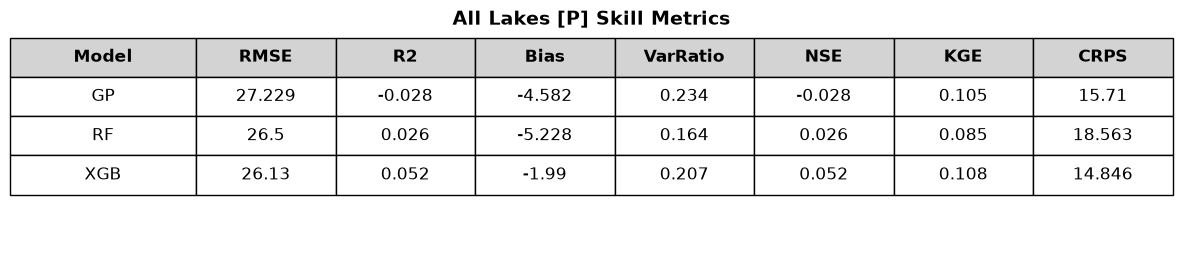

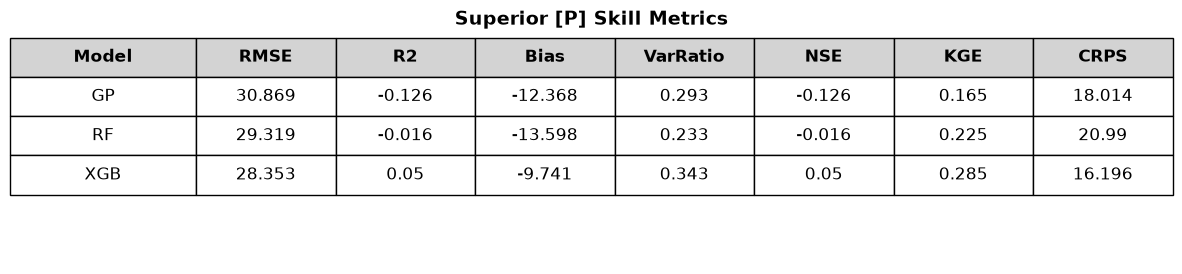

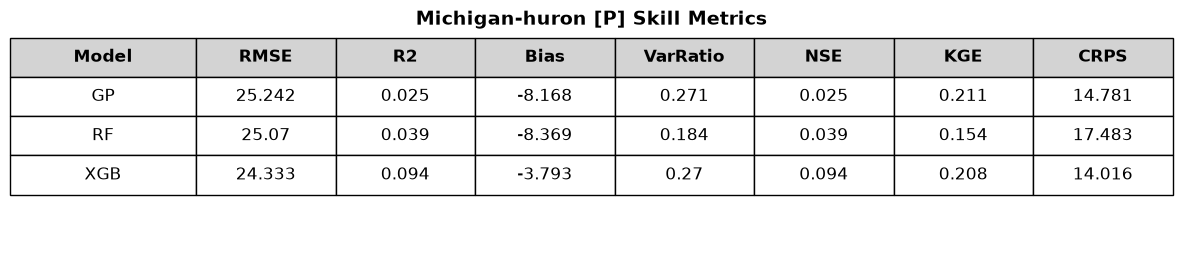

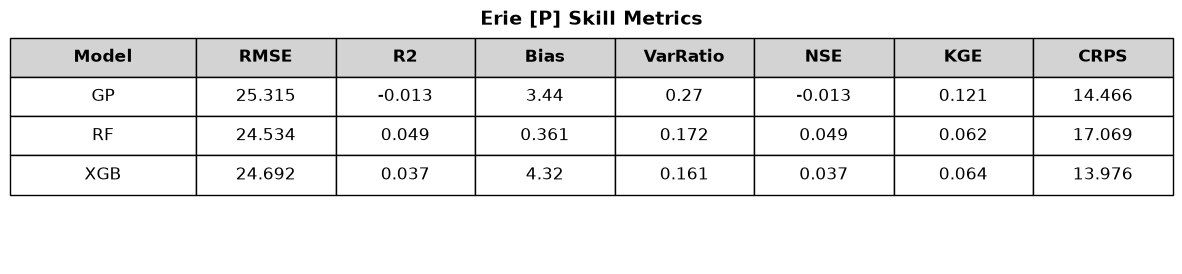

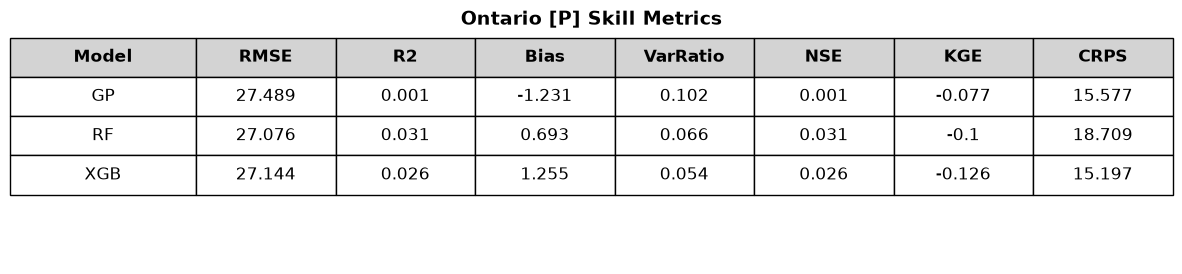

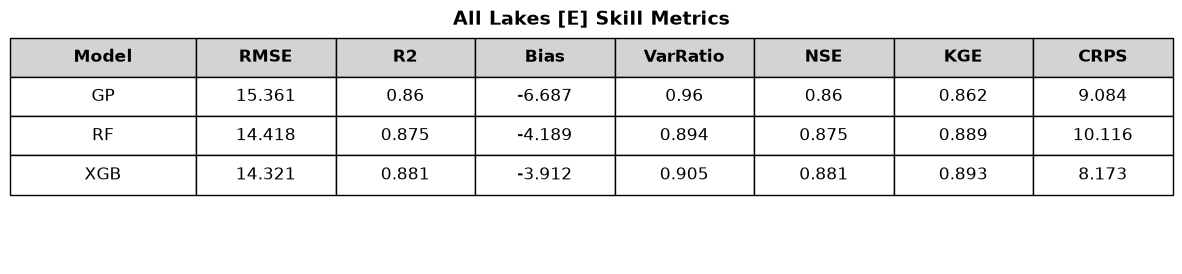

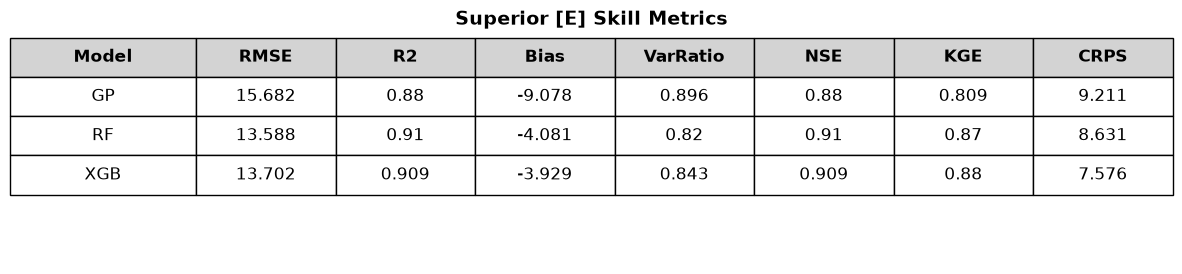

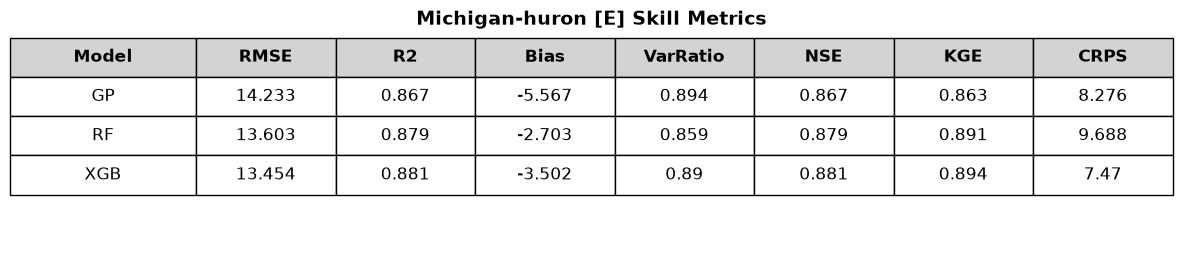

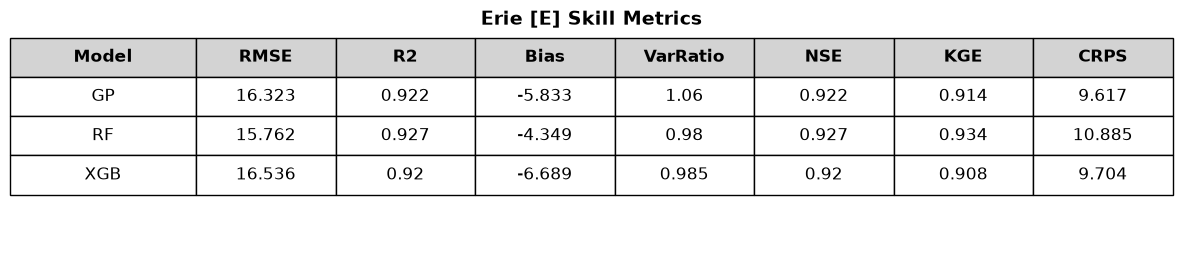

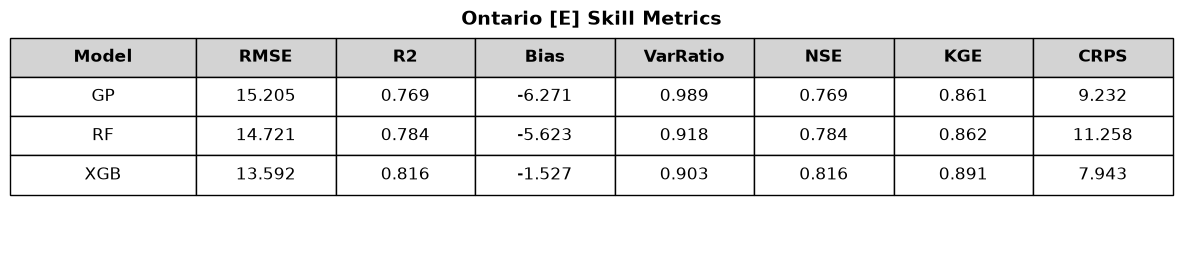

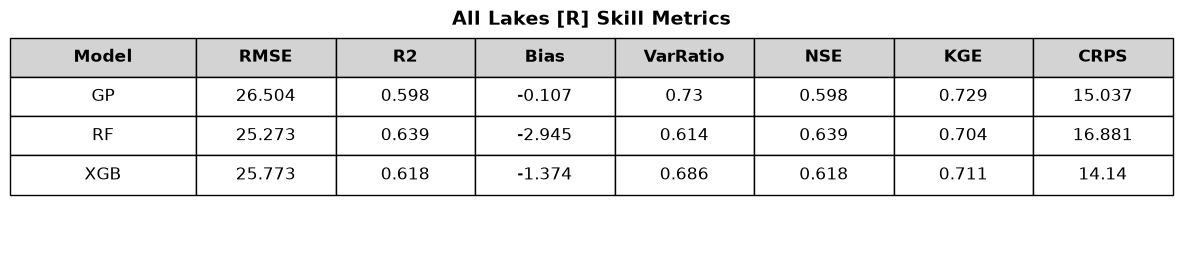

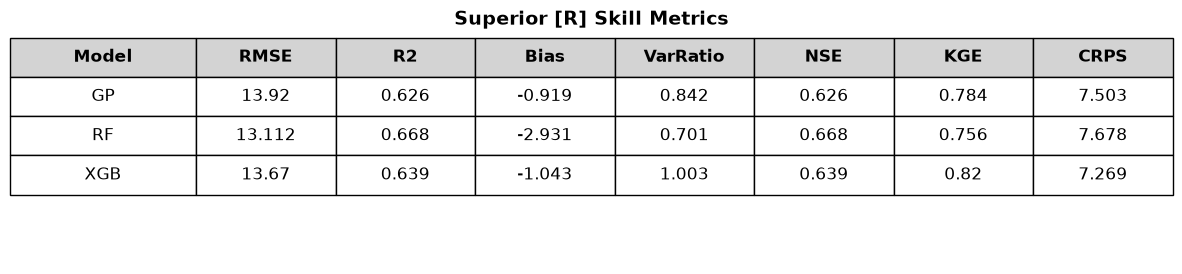

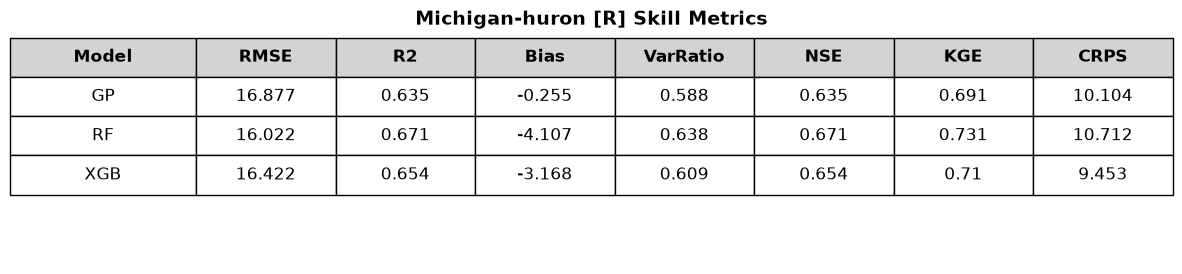

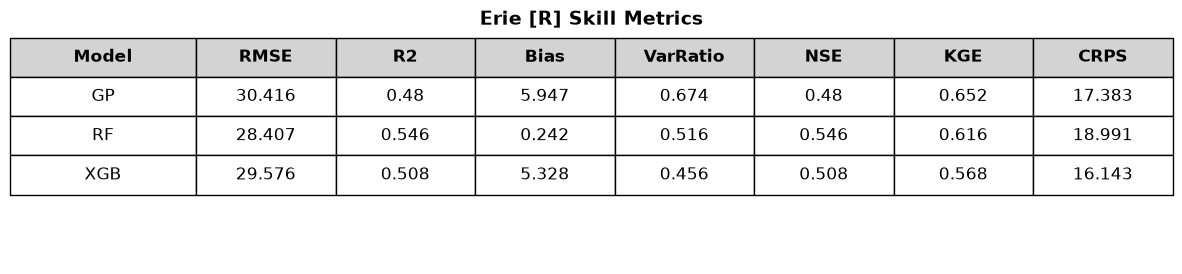

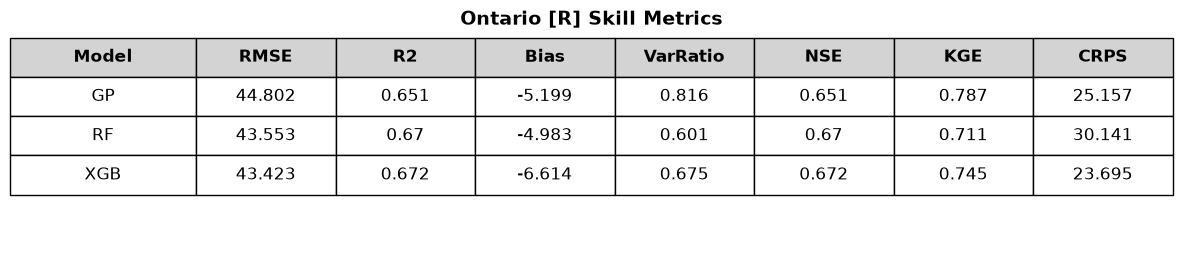

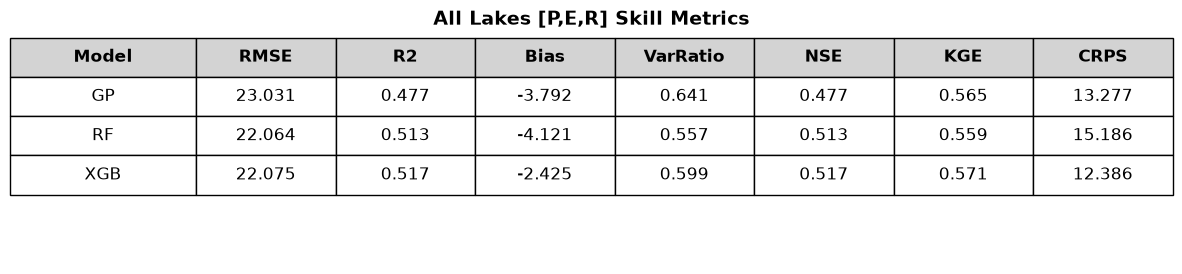

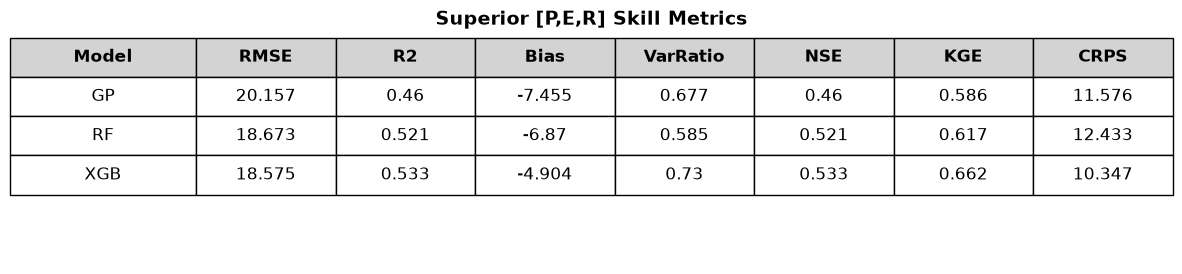

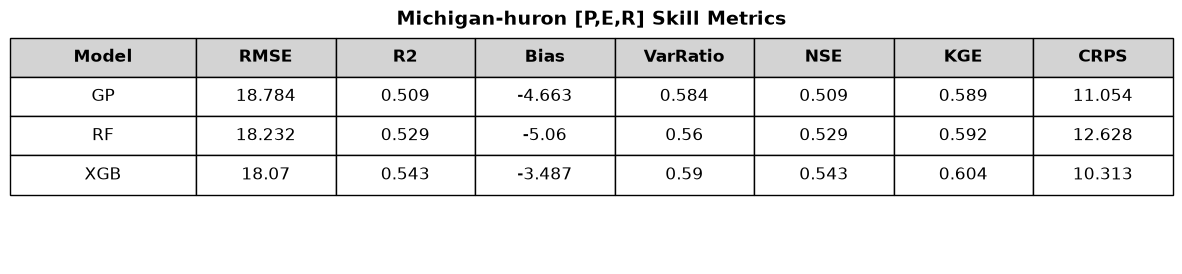

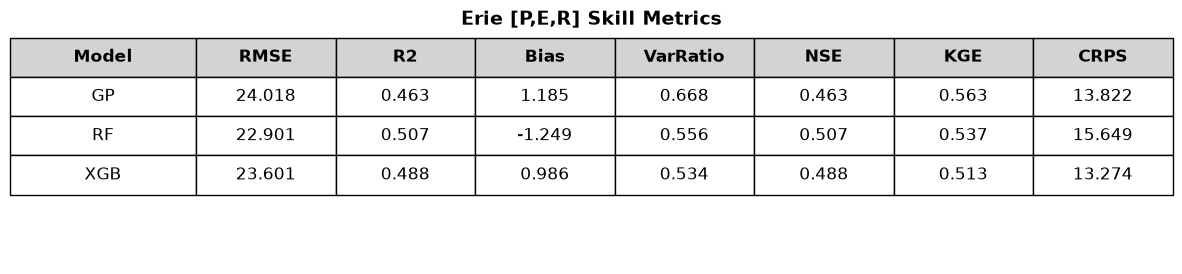

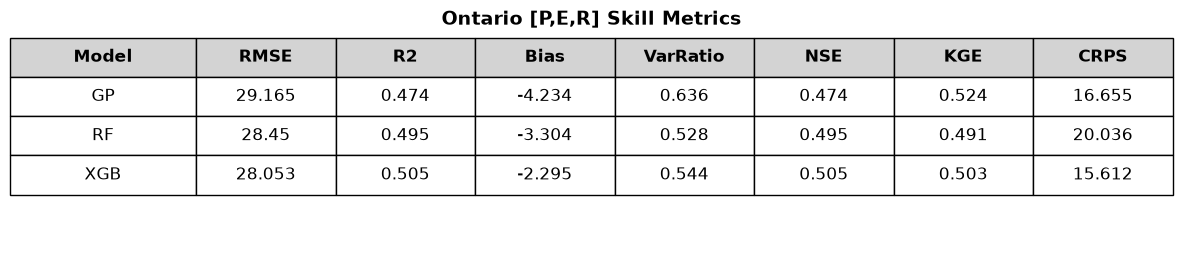

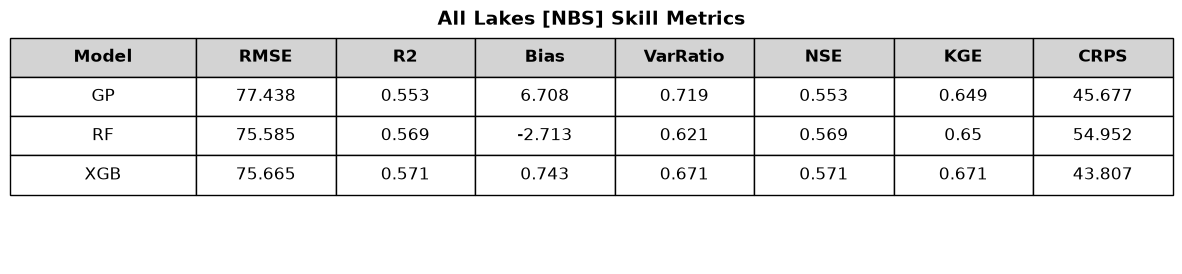

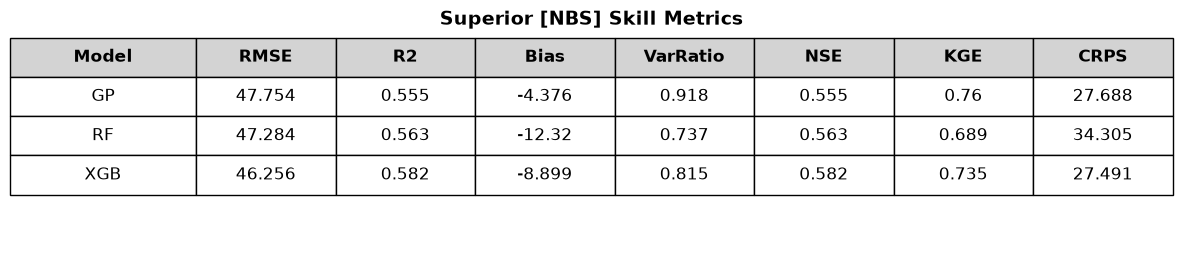

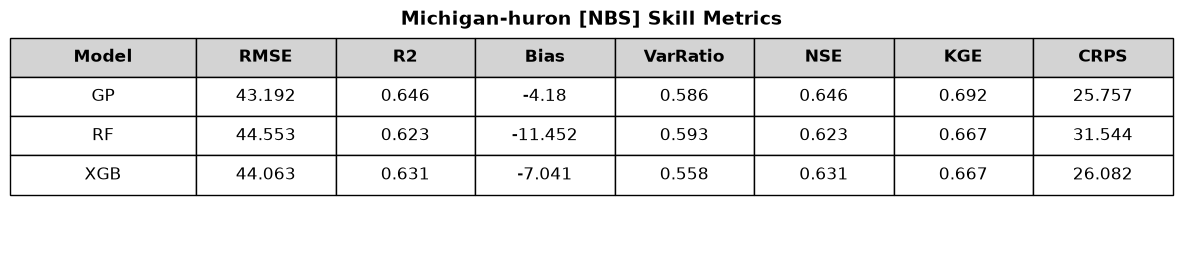

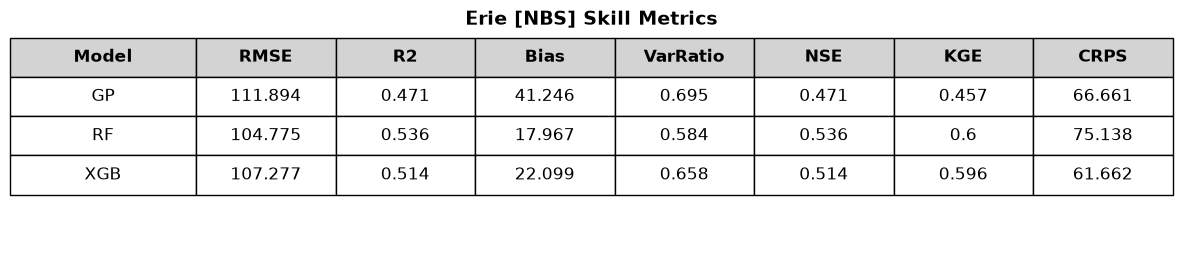

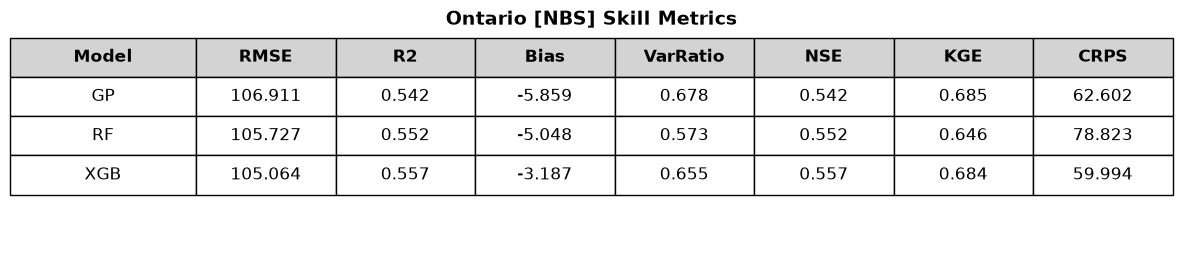

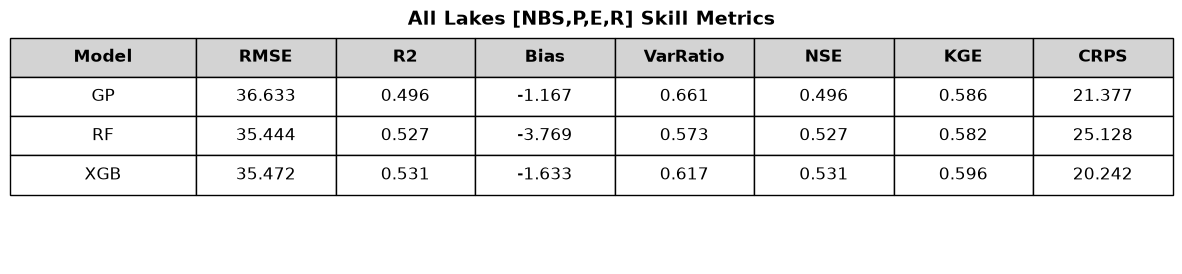

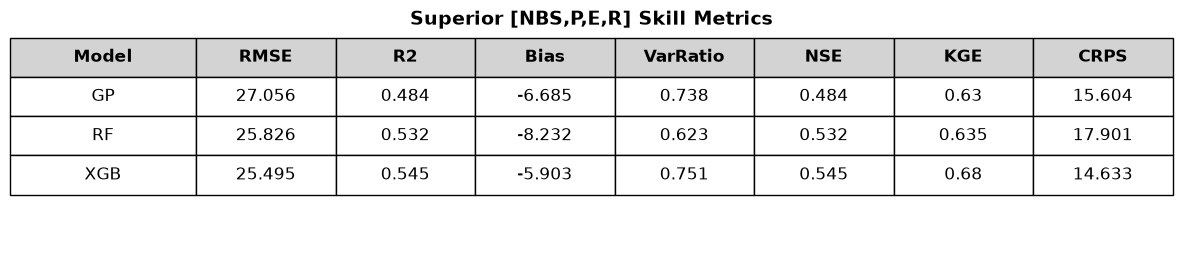

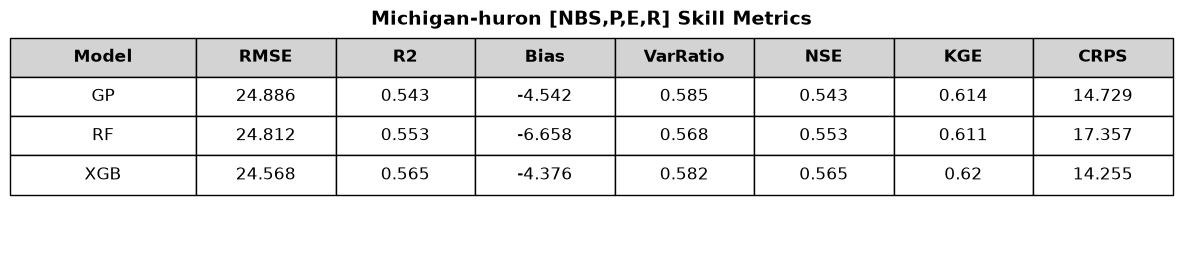

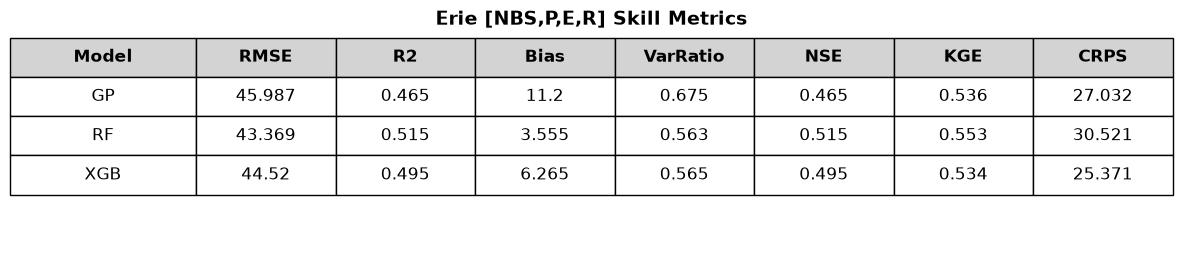

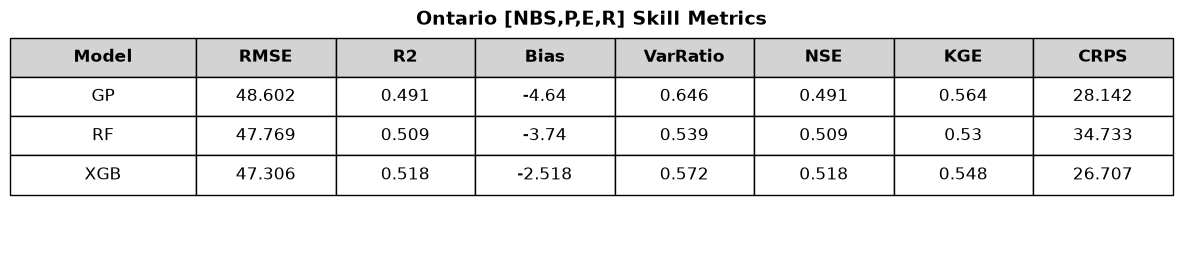

In [28]:
lakes = ['superior', 'michigan-huron', 'erie', 'ontario']

component_configs = [
    (['precipitation'], "[P] Skill Metrics"),
    (['evaporation'], "[E] Skill Metrics"),
    (['runoff'], "[R] Skill Metrics"),
    (['precipitation', 'evaporation', 'runoff'], "[P,E,R] Skill Metrics"),
    (['nbs'], "[NBS] Skill Metrics"),
    (['nbs', 'precipitation', 'evaporation', 'runoff'], "[NBS,P,E,R] Skill Metrics"),
]

selected_metrics = [
    'RMSE', 'R2',
    'Bias', 'VarRatio',
    'NSE', 'KGE', 
    'CRPS'
]

for components, title in component_configs:

    # =========================
    # ALL LAKES
    # =========================
    results = [
        compute_skill(
            df_combined,
            lakes=lakes,
            components=components,
            model=m,
            metrics=selected_metrics
        )
        for m in models
    ]

    df_all = pd.concat(results, ignore_index=True)
    df_all = df_all[['Model'] + selected_metrics]

    plot_styled_table(df_all, title=f"All Lakes {title}")

    # =========================
    # PER LAKE
    # =========================
    for lake in lakes:

        results = [
            compute_skill(
                df_combined,
                lakes=[lake],
                components=components,
                model=m,
                metrics=selected_metrics
            )
            for m in models
        ]

        df_lake = pd.concat(results, ignore_index=True)
        df_lake = df_lake[['Model'] + selected_metrics]

        plot_styled_table(df_lake, title=f"{lake.capitalize()} {title}")

In [ ]:
lakes = ['superior', 'michigan-huron', 'erie', 'ontario']
models = ['GP', 'RF', 'XGB']

component_configs = [
    (['precipitation'], "[P] Skill Metrics"),
    (['evaporation'], "[E] Skill Metrics"),
    (['runoff'], "[R] Skill Metrics"),
    (['precipitation', 'evaporation', 'runoff'], "[P,E,R] Skill Metrics"),
    (['nbs'], "[NBS] Skill Metrics"),
    (['nbs', 'precipitation', 'evaporation', 'runoff'], "[NBS,P,E,R] Skill Metrics"),
]

selected_metrics = [
    'RMSE', 'RMSE_ext',
    'R2', 'R2_ext',
    'Bias', 'Bias_ext'
]

 

In [35]:
print(df_tidy)

        init_time  member model forecast_month  erie_evaporation    erie_nbs  \
0      1991-03-01       0    GP        1991-03          7.148939  436.248797   
1      1991-03-01       0    GP        1991-04         12.832140  298.712643   
2      1991-03-01       0    GP        1991-05         15.682239  166.019359   
3      1991-03-01       0    GP        1991-06         28.367327  107.385858   
4      1991-03-01       0    GP        1991-07         75.748290   72.866007   
...           ...     ...   ...            ...               ...         ...   
110443 2025-11-01      10   XGB        2026-06         30.688372  148.428490   
110444 2025-11-01      10   XGB        2026-07         72.509554   84.306805   
110445 2025-11-01      10   XGB        2026-08        102.379926    4.873527   
110446 2025-11-01      10   XGB        2026-09        174.517679  -74.339686   
110447 2025-11-01      10   XGB        2026-10        171.111458 -112.288670   

        erie_precipitation  erie_runoff

In [37]:
#df_tidy['cfs_run'] = pd.to_datetime(df_tidy['cfs_run'])
#df_tidy['forecast_month'] = pd.to_datetime(df_tidy['forecast_month'])

# For each forecast run, keep only the first 6 months
df_first6 = (
    df_combined.sort_values(['init_time', 'forecast_month'])
      .groupby(['init_time', 'model'])
      .head(6)  # keep first 6 rows per run/model
      .reset_index(drop=True)
)

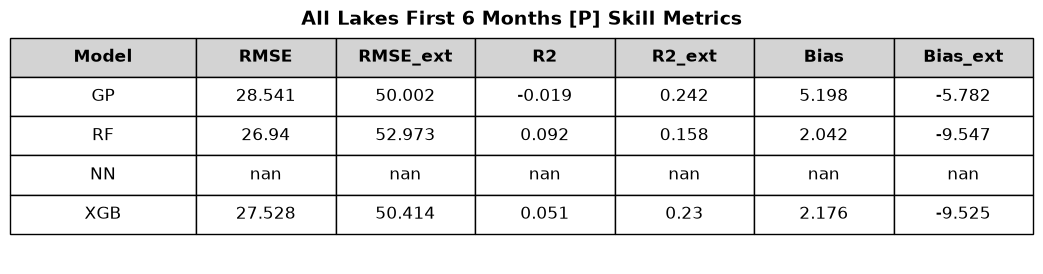

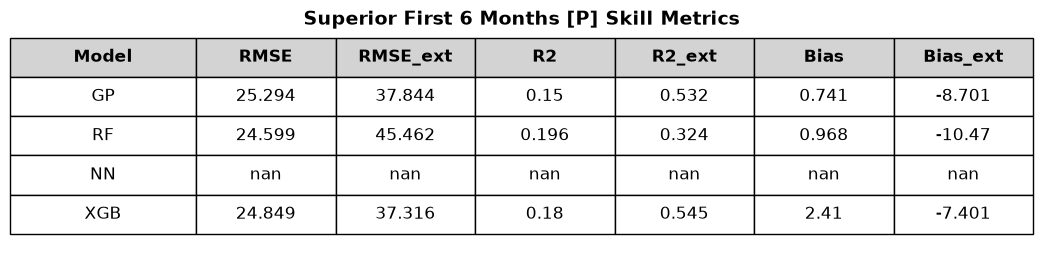

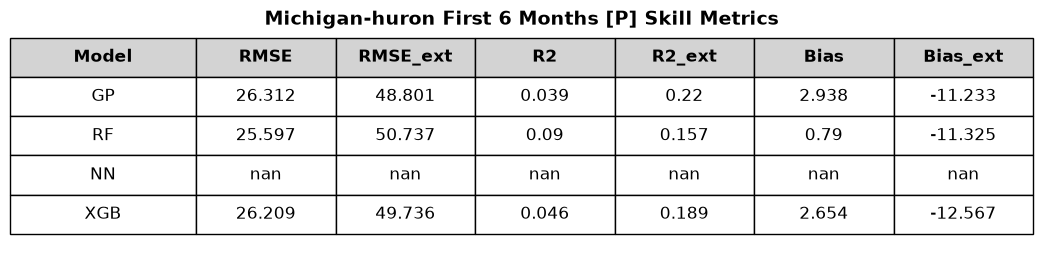

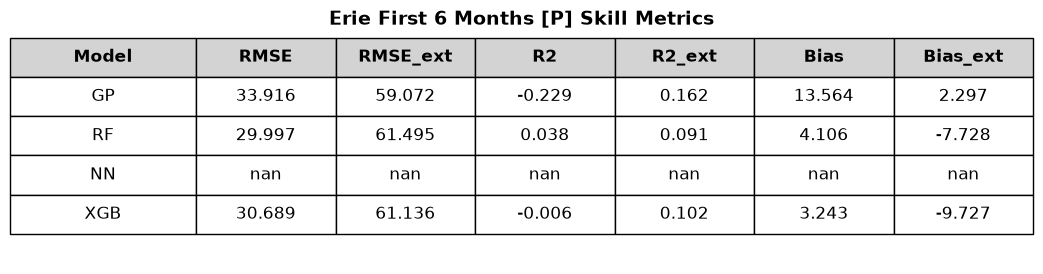

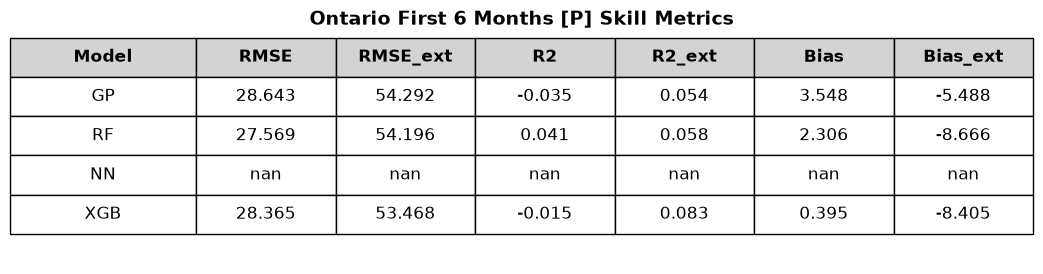

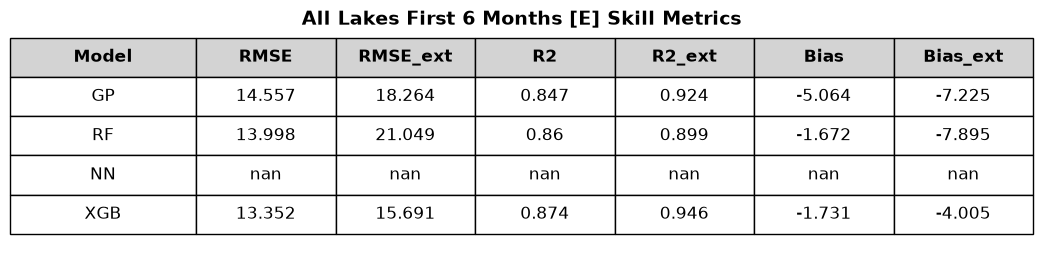

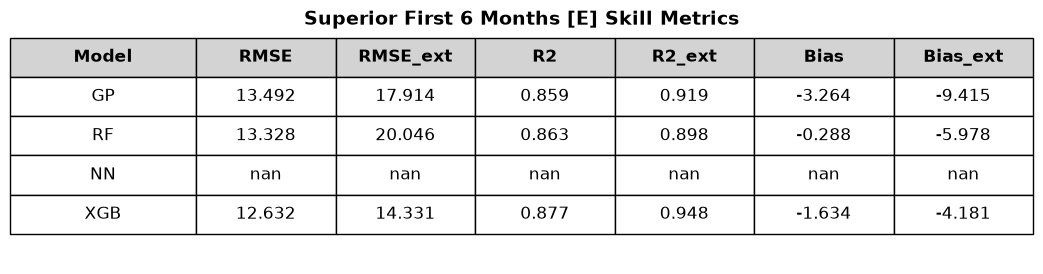

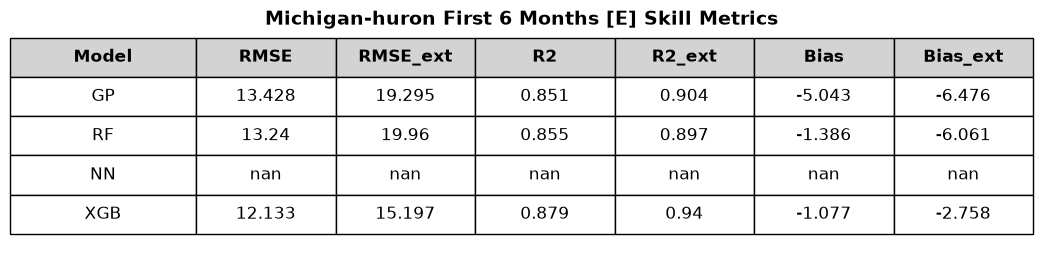

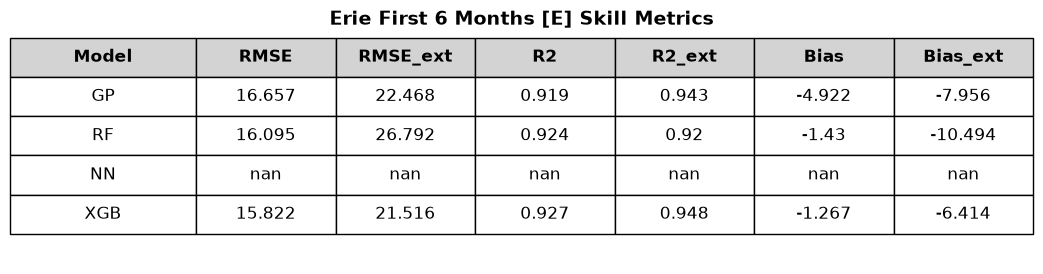

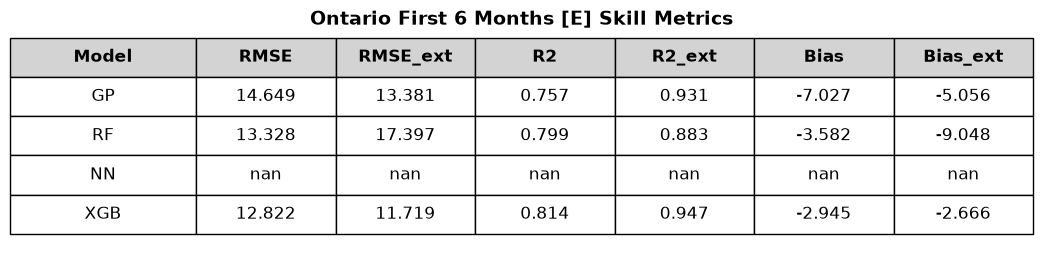

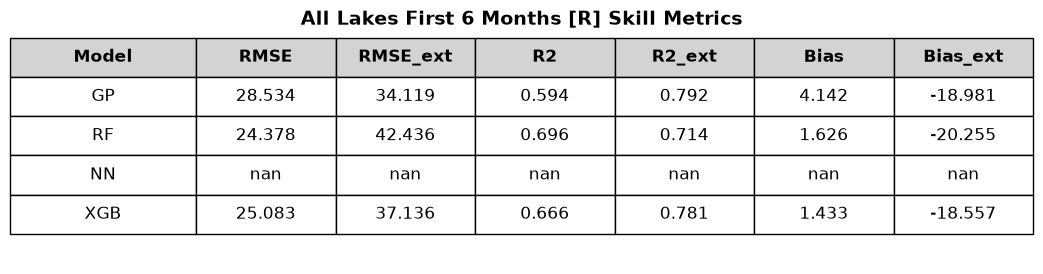

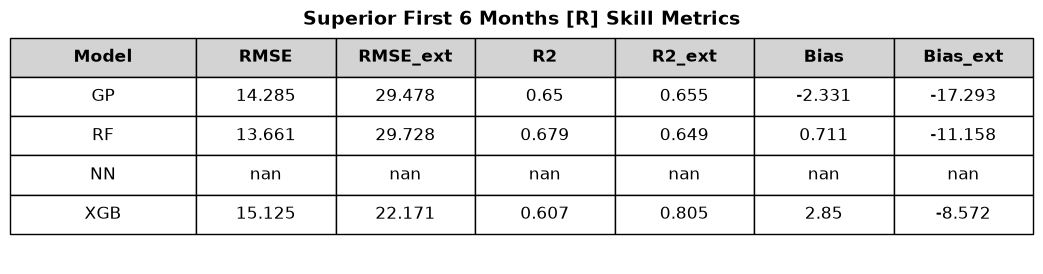

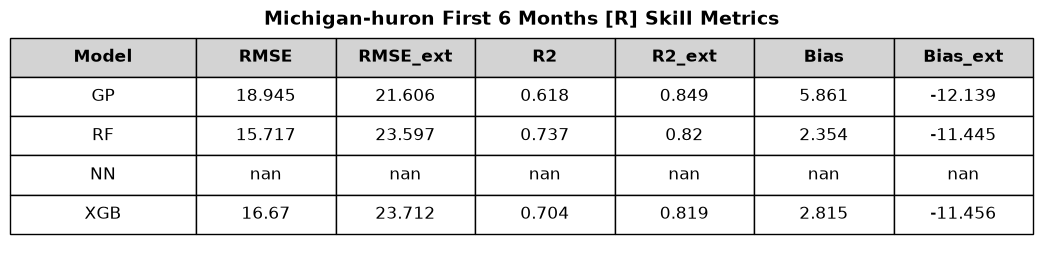

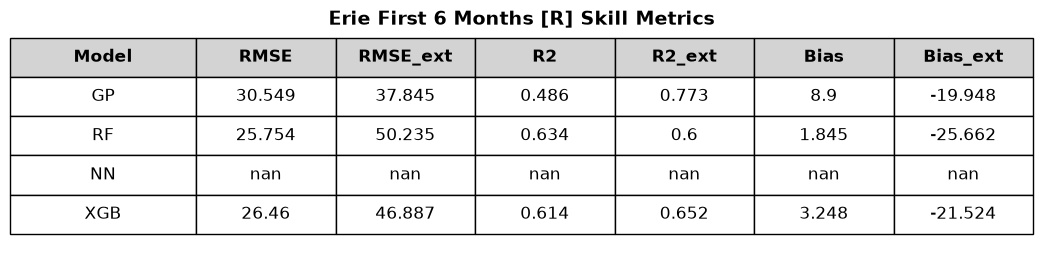

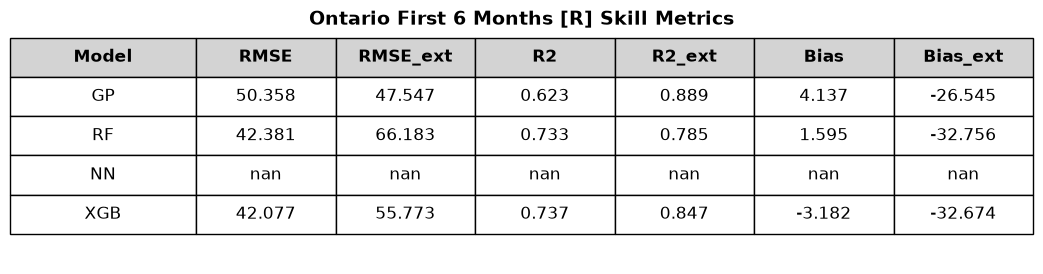

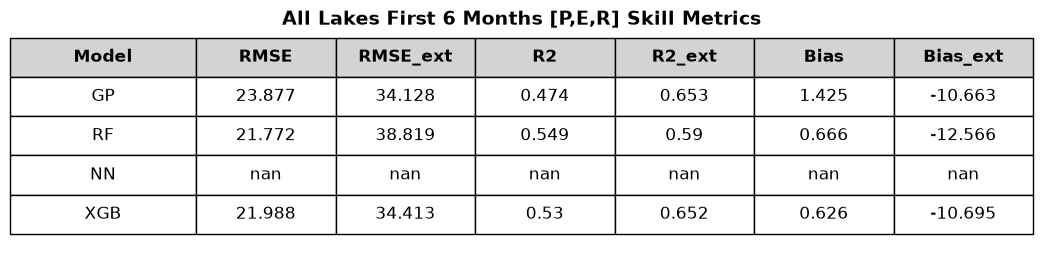

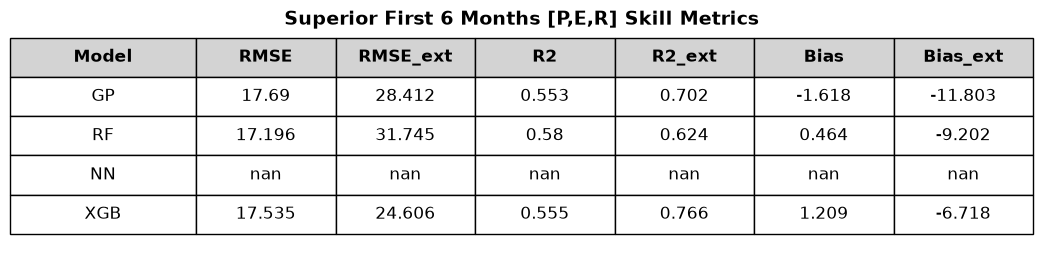

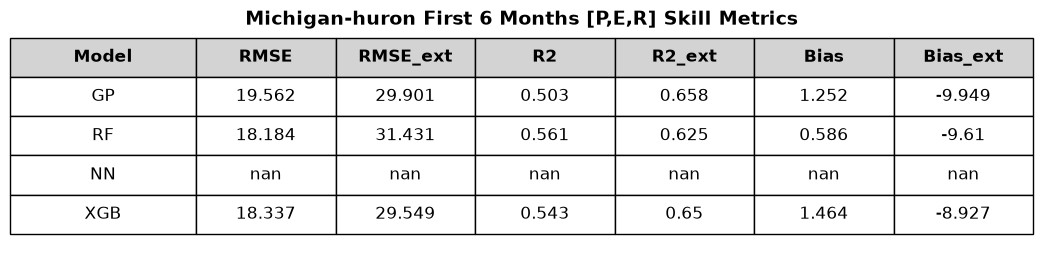

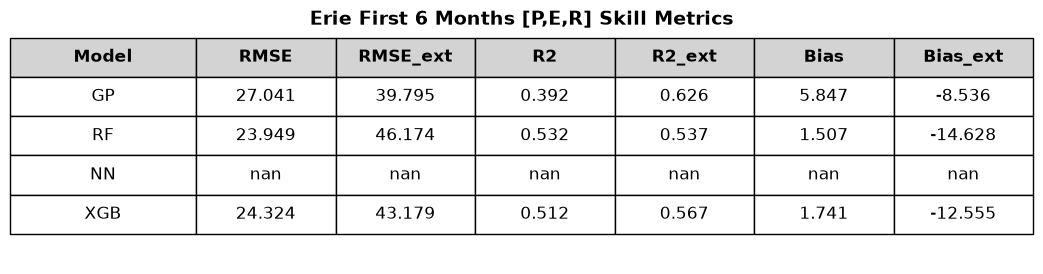

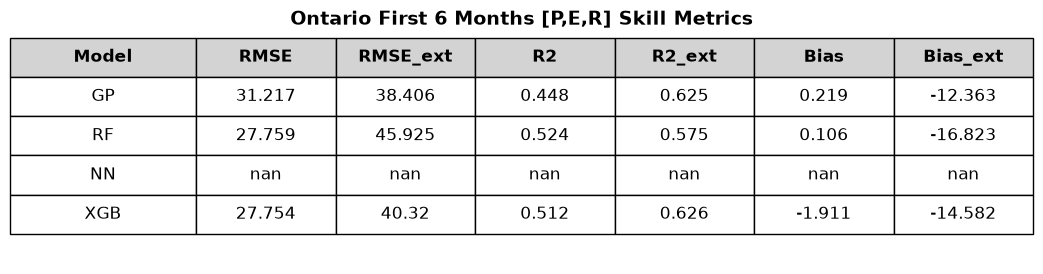

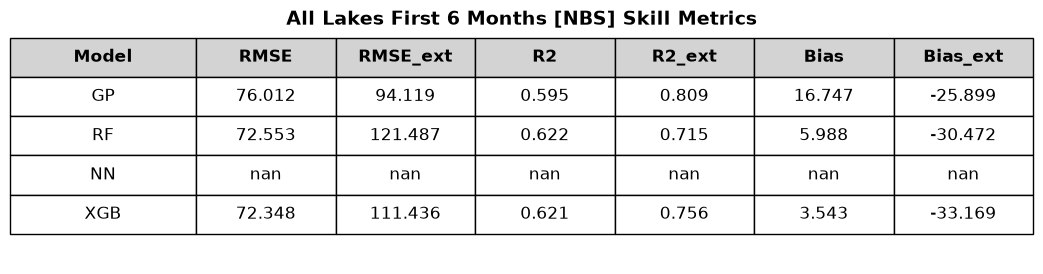

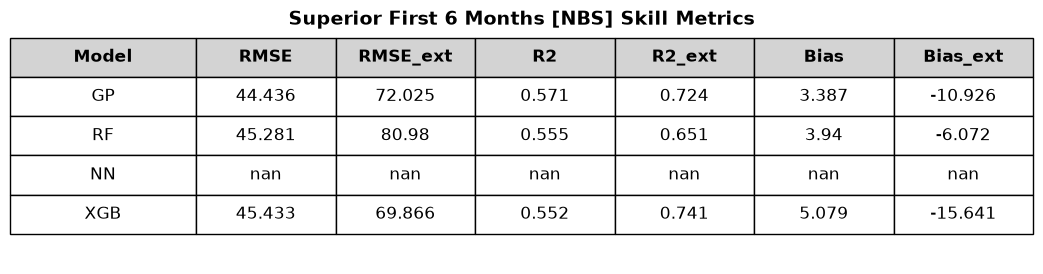

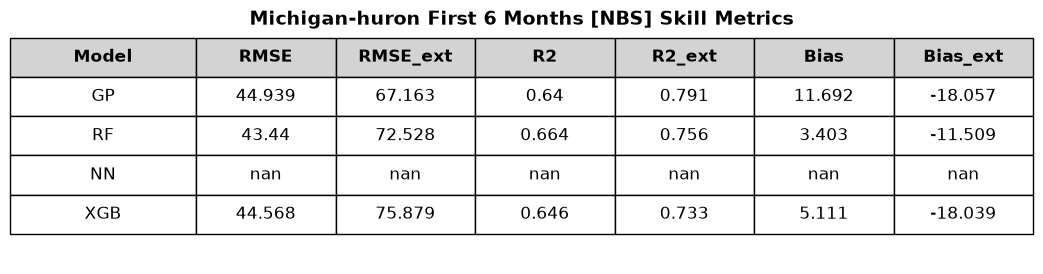

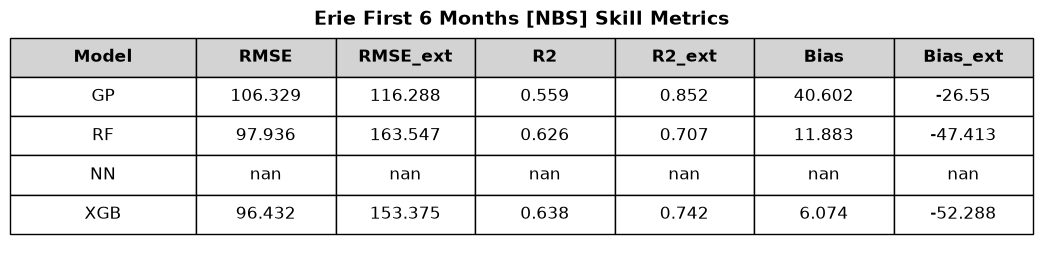

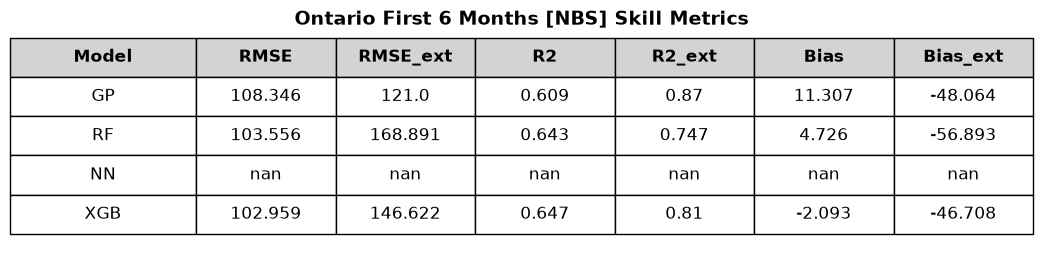

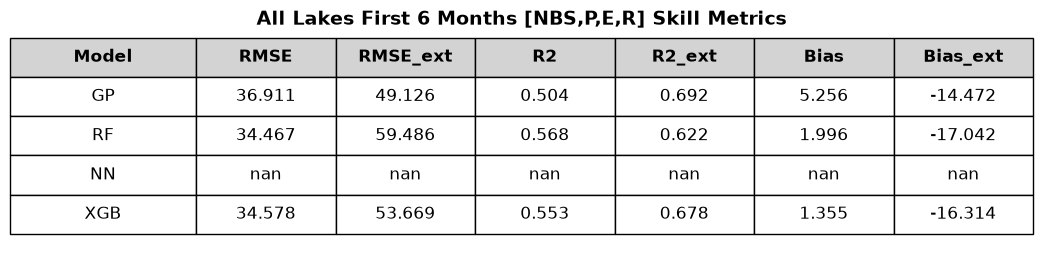

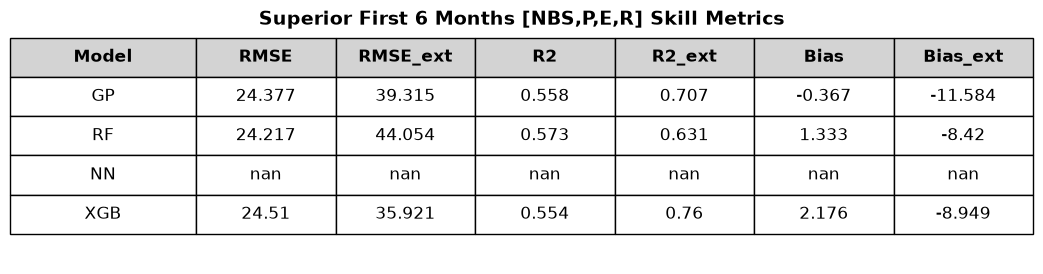

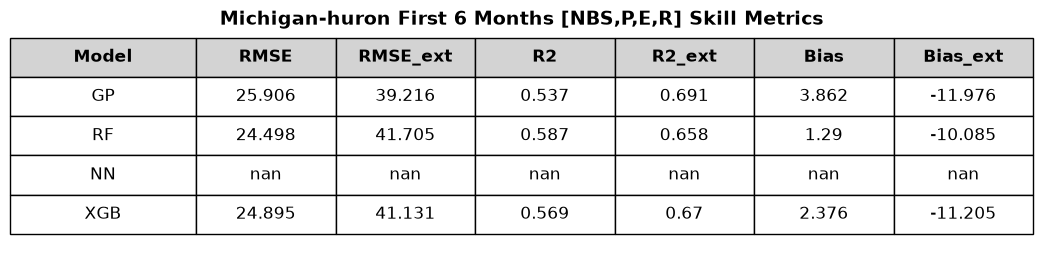

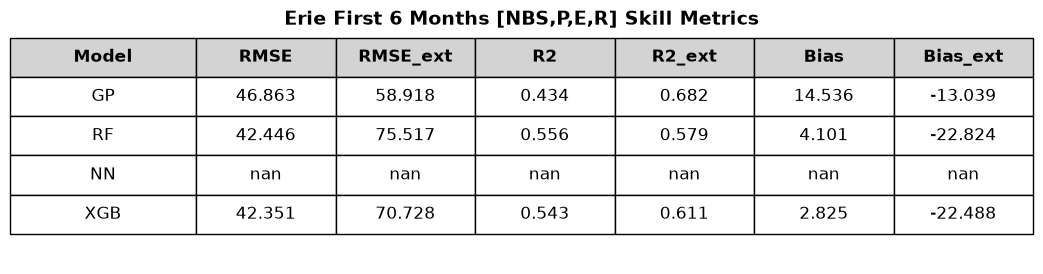

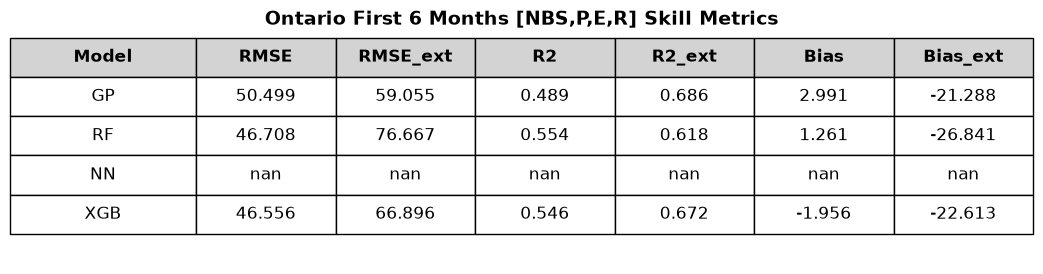

In [ ]:
# lakes and models stay constant
lakes = ['superior', 'michigan-huron', 'erie', 'ontario']
models = ['GP', 'RF', 'XGB']

# component configurations and plot titles
component_configs = [
    (['precipitation'], "First 6 Months [P] Skill Metrics"),
    (['evaporation'], "First 6 Months [E] Skill Metrics"),
    (['runoff'], "First 6 Months [R] Skill Metrics"),
    (['precipitation', 'evaporation', 'runoff'], "First 6 Months [P,E,R] Skill Metrics"),
    (['nbs'], "First 6 Months [NBS] Skill Metrics"),
    (['nbs', 'precipitation', 'evaporation', 'runoff'], "First 6 Months [NBS,P,E,R] Skill Metrics"),
]

for components, title in component_configs:

    # =========================
    # ALL LAKES
    # =========================
    results = [
        compute_skill(
            df_first6,
            lakes=lakes,
            components=components,
            model=m,
            metrics=selected_metrics
        )
        for m in models
    ]

    df_all = pd.concat(results, ignore_index=True)
    df_all = df_all[['Model'] + selected_metrics]

    plot_styled_table(df_all, title=f"All Lakes {title}")

    # =========================
    # PER LAKE
    # =========================
    for lake in lakes:

        results = [
            compute_skill(
                df_first6,
                lakes=[lake],
                components=components,
                model=m,
                metrics=selected_metrics
            )
            for m in models
        ]

        df_lake = pd.concat(results, ignore_index=True)
        df_lake = df_lake[['Model'] + selected_metrics]

        plot_styled_table(df_lake, title=f"{lake.capitalize()} {title}")

In [39]:
print(data)

         init_time  member  lead  valid_time      lake surface_type  \
0       1991-03-01       0     0  1991-03-01      erie         lake   
1       1991-03-01       0     0  1991-03-01      erie         lake   
2       1991-03-01       0     0  1991-03-01      erie         lake   
3       1991-03-01       0     0  1991-03-01      erie         land   
4       1991-03-01       0     0  1991-03-01      erie         land   
...            ...     ...   ...         ...       ...          ...   
883867  2025-11-01      10    11  2026-10-01  superior         lake   
883868  2025-11-01      10    11  2026-10-01  superior         lake   
883869  2025-11-01      10    11  2026-10-01  superior         land   
883870  2025-11-01      10    11  2026-10-01  superior         land   
883871  2025-11-01      10    11  2026-10-01  superior         land   

               component       value  
0        air_temperature  274.068451  
1       latent_heat_flux    5.852441  
2          precipitation  122.

In [ ]:
df = data.copy()

df["date"] = pd.to_datetime(df["year"].astype(str) + "-" + df["month"].astype(str) + "-01")

# 2. Filter only surface_type == lake
df = df[df["surface_type"] == "lake"]

# 3. Create "variable" column
df["variable"] = df["lake"] + "_" + df["component"]

# 4. Pivot to wide format
pivot_df = df.pivot_table(
    index=["date", "cfs_run"],  # keep these as identifiers
    columns="variable",
    values="value [mm]",
    aggfunc="mean"  # in case of duplicates
).reset_index()

# Optional: flatten column names after pivot
pivot_df.columns.name = None  # remove pivot column grouping name

df_cfs_mean =(pivot_df.groupby(["date"]).mean(numeric_only=True))
df_cfs = df_cfs_mean.reset_index()

In [ ]:
df_mean = df_combined.groupby(['forecast_month','model']).mean()
df_mean = df_mean.reset_index()

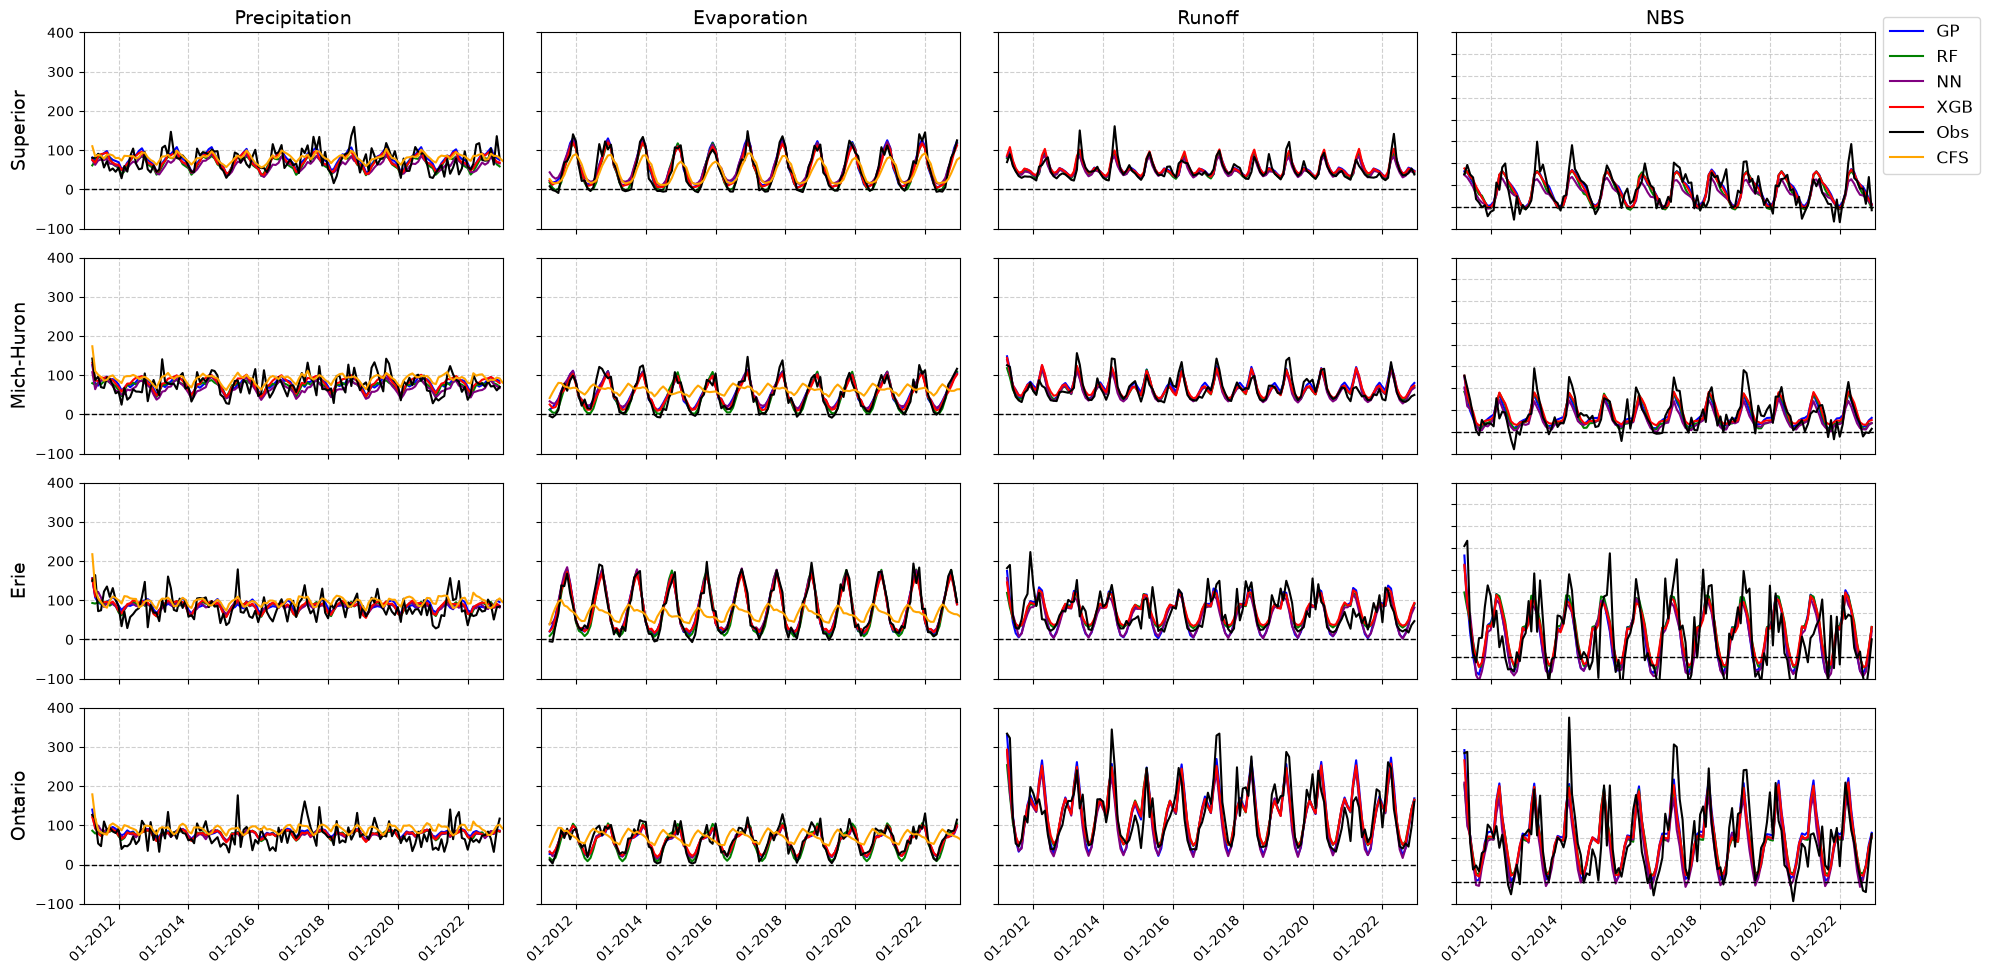

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd #Define model colors
model_colors = {'GP': 'blue', 'RF': 'green', 'XGB': 'red', 'NN': 'purple'}
# Define lake names and components
lakes = ['superior', 'michigan-huron', 'erie', 'ontario']
components = ['precipitation', 'evaporation', 'runoff', 'nbs']
titles = ['Precipitation', 'Evaporation', 'Runoff', 'NBS']
ylabels = ['Superior', 'Mich-Huron', 'Erie', 'Ontario']

# Create subplot grid
fig, axs = plt.subplots(4, 4, figsize=(20, 10))
axs = axs.reshape(4, 4)

# Loop through all combinations of lake and component
for row, lake in enumerate(lakes):
    for col, comp in enumerate(components):
        ax = axs[row, col]
        column = f'{lake}_{comp}'
        obs_column = f'{column}_obs'

        for model_name in models_list:
            model_df = df_mean[df_mean['model'] == model_name].copy()
            
            # Plot model prediction
            ax.plot(model_df['date'], model_df[column],
                    color=model_colors[model_name], label=model_name)

        # Plot observations
        ax.plot(model_df['date'], model_df[obs_column],
                color='black', linewidth=1.5, label='Obs')

        # Only plot CFS for precipitation + evaporation
        if comp in ['precipitation', 'evaporation']:
            ax.plot(df_cfs['date'], df_cfs[column],
                    color='orange', linewidth=1.5, label='CFS')
        
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.set_yticks(np.arange(-1000, 1000, 100))

        # Set titles and labels
        if row == 0:
            ax.set_title(titles[col], fontsize=14)
        if row == 3:
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%Y'))
            ax.tick_params(axis='x', rotation=45)
            for label in ax.get_xticklabels():
                label.set_horizontalalignment('right')
        else:
            ax.set_xticklabels([])

        if col == 0:
            ax.set_ylabel(ylabels[row], fontsize=14)
        else:
            ax.set_yticklabels([])
        if col == 3:
            ax.set_ylim(-100, 800)
        else:
            ax.set_ylim(-100, 400)

# Get handles and labels from (0,0)
handles, labels = axs[0, 0].get_legend_handles_labels()

# Place legend in (0,3) using those colors
axs[0, 3].legend(
    handles,
    labels,
    loc='lower left',
    bbox_to_anchor=(1, 0.236),
    fontsize=12
)

start_date = pd.to_datetime('2011-01-01')
end_date = pd.to_datetime('2023-01-01')

for ax_row in axs:
    for ax in ax_row:
        ax.set_xlim(start_date, end_date)

# Save and show plot
plt.tight_layout()
plt.savefig('CNBS_forecasts.png', dpi=300)
plt.show()

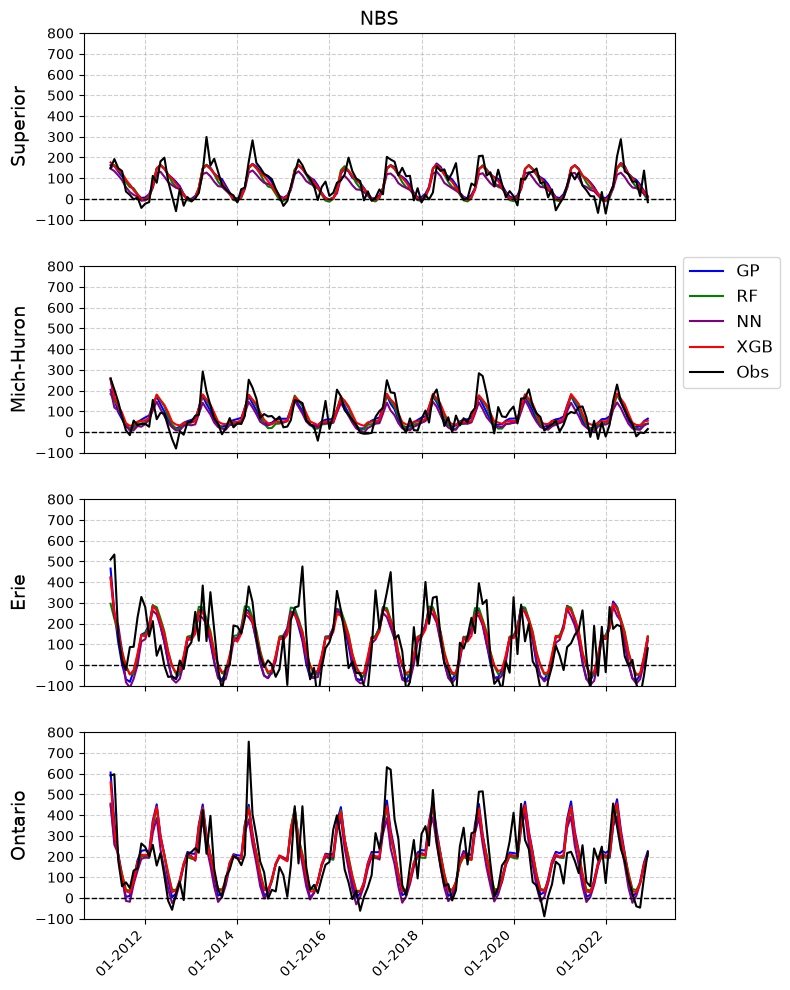

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

# Define model colors
model_colors = {'GP': 'blue', 'RF': 'green', 'XGB': 'red', 'NN': 'purple'}

# Define lake names and components
lakes = ['superior', 'michigan-huron', 'erie', 'ontario']
components = ['nbs']
titles = ['NBS']
ylabels = ['Superior', 'Mich-Huron', 'Erie', 'Ontario']

# Create subplot grid
fig, axs = plt.subplots(4, 1, figsize=(8, 10))
axs = axs.reshape(4, 1)

# Loop through all combinations of lake and component
for row, lake in enumerate(lakes):
    for col, comp in enumerate(components):
        ax = axs[row, col]
        column = f'{lake}_{comp}'
        obs_column = f'{column}_obs'

        for model_name in models_list:
            model_df = df_mean[df_mean['model'] == model_name].copy()
            
            # Plot model prediction
            ax.plot(model_df['date'], model_df[column],
                    color=model_colors[model_name], label=model_name)

        # Plot observations
        ax.plot(model_df['date'], model_df[obs_column],
                color='black', linewidth=1.5, label='Obs')

        # Only plot CFS for precipitation + evaporation
        if comp in ['precipitation', 'evaporation']:
            ax.plot(df_cfs['date'], df_cfs[column],
                    color='orange', linewidth=1.5, label='CFS')
        
        ax.axhline(0, color='black', linestyle='--', linewidth=1)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.set_yticks(np.arange(-1000, 1000, 100))

        # Set titles and labels
        if row == 0:
            ax.set_title(titles[col], fontsize=14)
        if row == 3:
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%Y'))
            ax.tick_params(axis='x', rotation=45)
            for label in ax.get_xticklabels():
                label.set_horizontalalignment('right')
        else:
            ax.set_xticklabels([])

        if col == 0:
            ax.set_ylabel(ylabels[row], fontsize=14)
        else:
            ax.set_yticklabels([])
        if col == 3:
            ax.set_ylim(-100, 800)
        else:
            ax.set_ylim(-100, 800)

# Add legend once
axs[1, 0].legend(loc='lower left', bbox_to_anchor=(1, 0.3), fontsize=12)

start_date = pd.to_datetime('2014-01-01')
end_date = pd.to_datetime('2015-01-01')

#for ax_row in axs:
#    for ax in ax_row:
#        ax.set_xlim(start_date, end_date)

# Save and show plot
plt.tight_layout()
plt.savefig('NBS_forecasts.png', dpi=300)
plt.show()

Calculate skill metrics based on month and season

In [ ]:
import pandas as pd

# ensure datetime
df = df_combined.copy()
df['forecast_month_dt'] = pd.to_datetime(df['forecast_month'])

# numeric month (1–12)
df['month'] = df['forecast_month_dt'].dt.month

# month name (Jan, Feb, etc.) – optional but nice for plots
df['month_name'] = df['forecast_month_dt'].dt.strftime('%b')


In [ ]:
def month_to_season(month):
    if month in [12, 1, 2]:
        return 'DJF'
    elif month in [3, 4, 5]:
        return 'MAM'
    elif month in [6, 7, 8]:
        return 'JJA'
    else:
        return 'SON'

df['season'] = df['month'].apply(month_to_season)


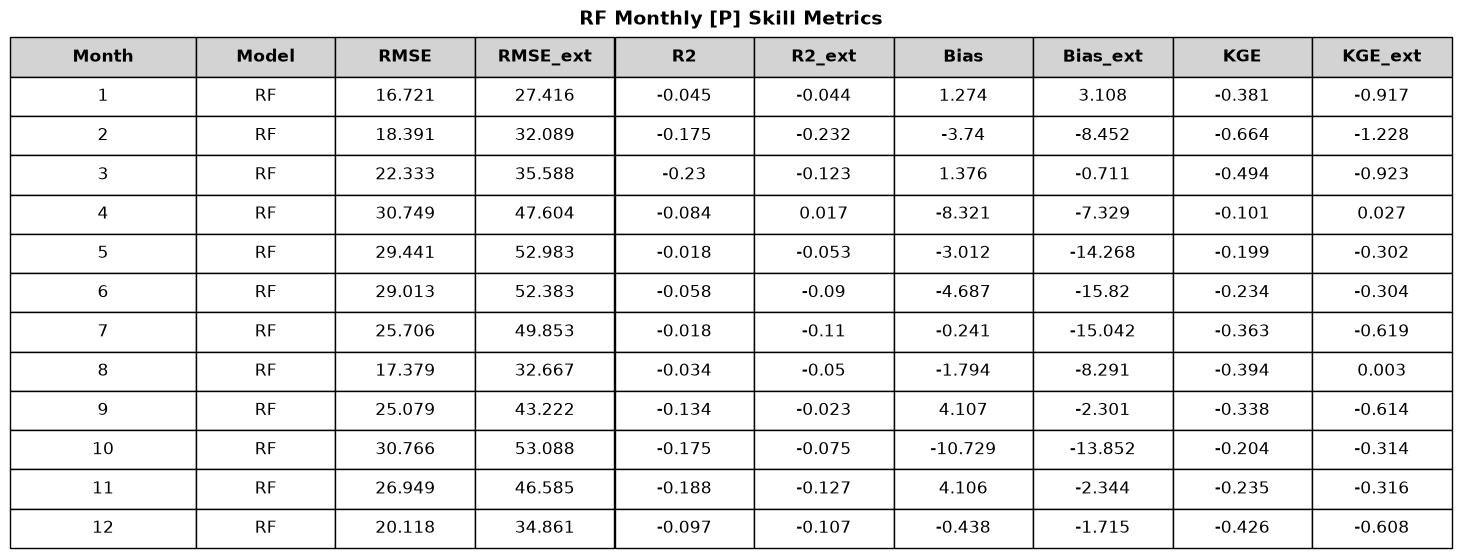

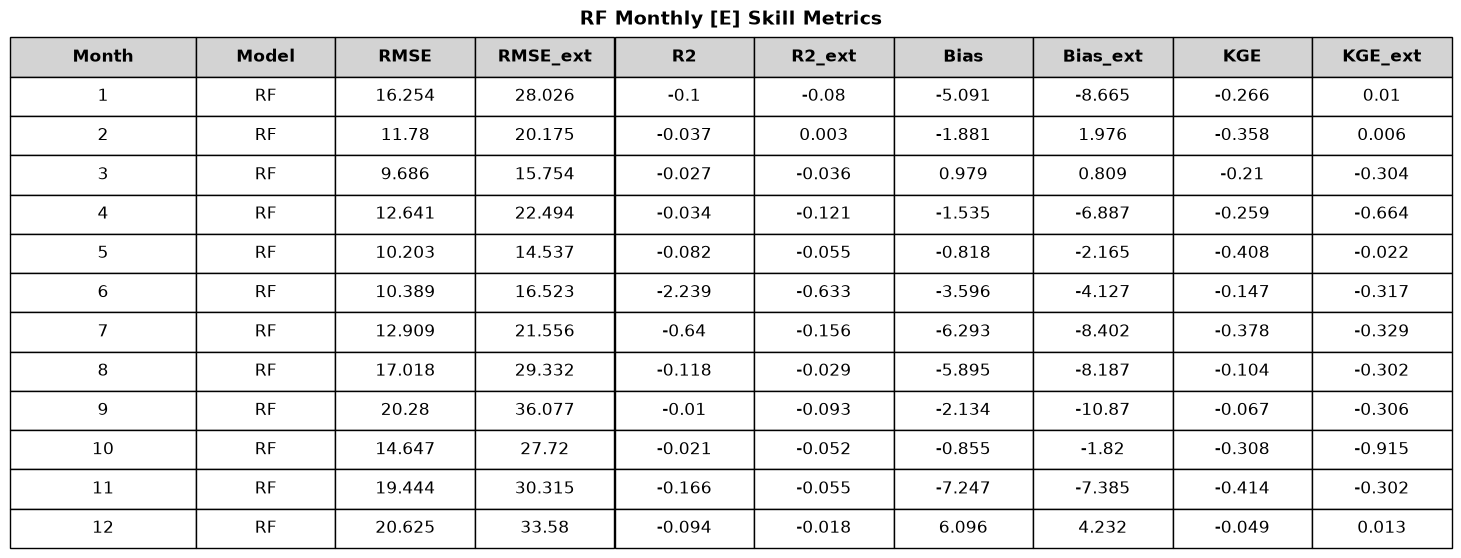

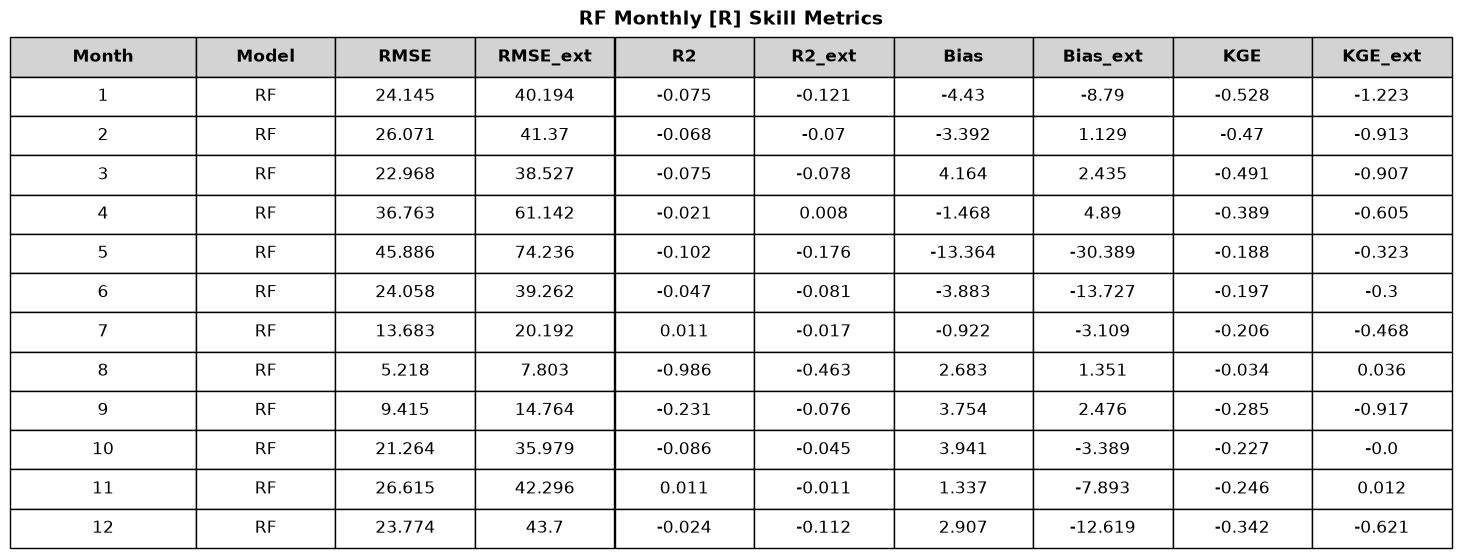

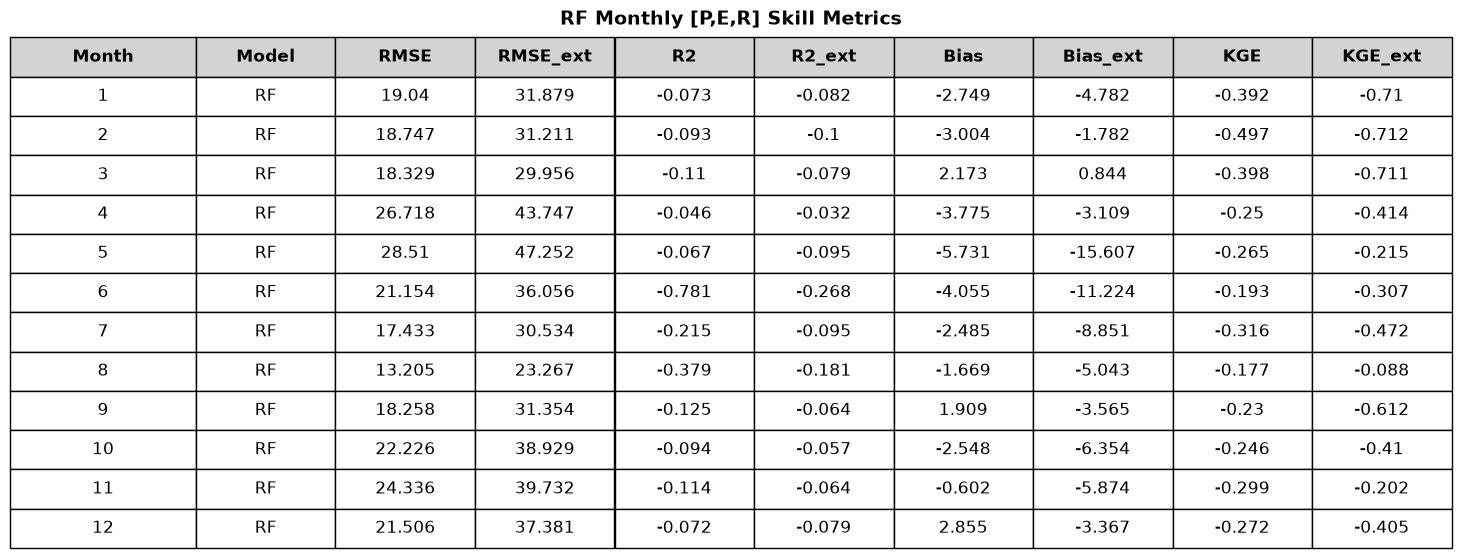

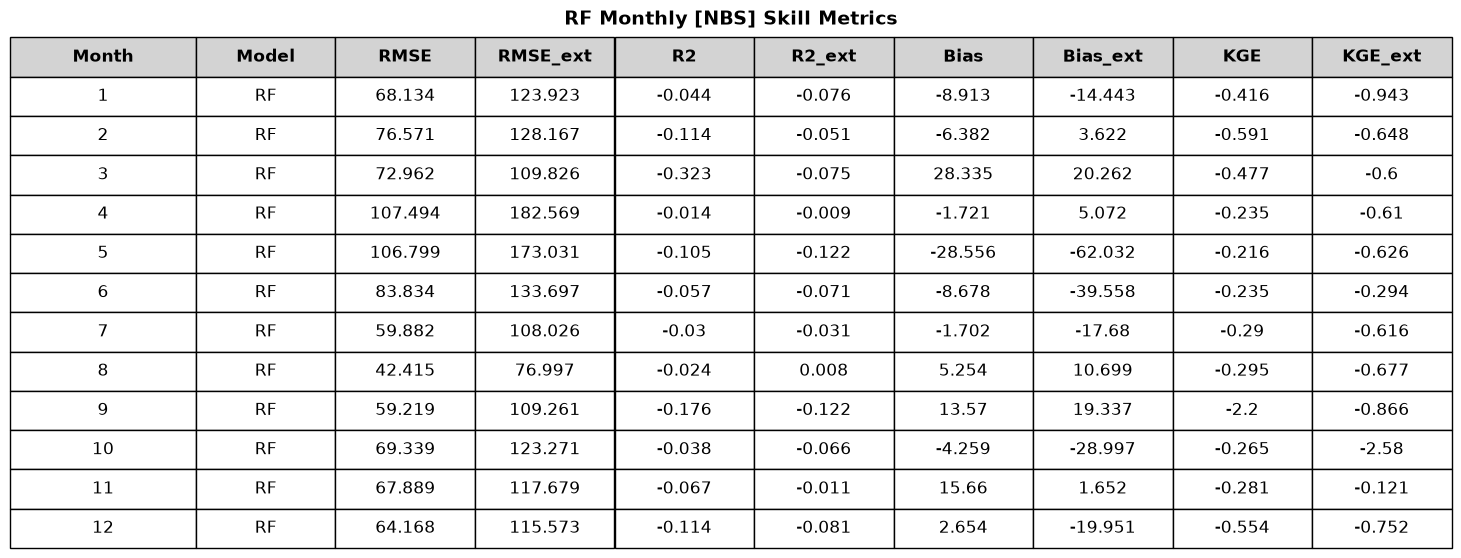

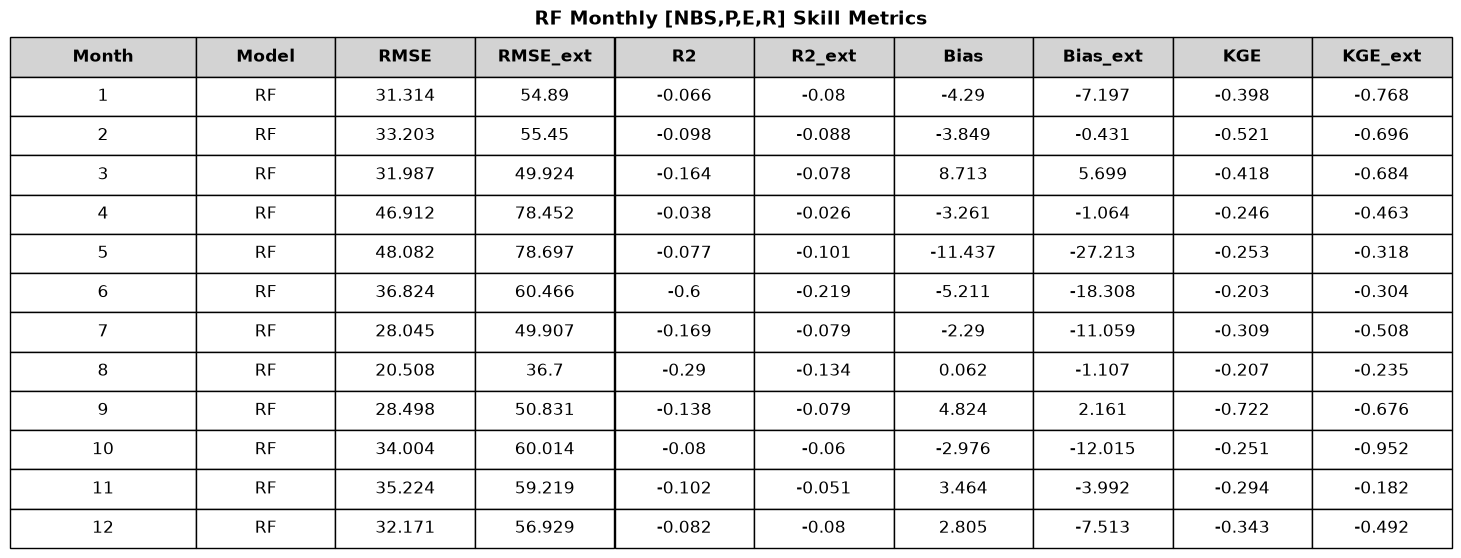

In [ ]:
# lakes and models stay constant
lakes = ['superior', 'michigan-huron', 'erie', 'ontario']
models = ['RF']

# component configurations and plot titles
component_configs = [
    (['precipitation'], "RF Monthly [P] Skill Metrics"),
    (['evaporation'], "RF Monthly [E] Skill Metrics"),
    (['runoff'], "RF Monthly [R] Skill Metrics"),
    (['precipitation', 'evaporation', 'runoff'], "RF Monthly [P,E,R] Skill Metrics"),
    (['nbs'], "RF Monthly [NBS] Skill Metrics"),
    (['nbs', 'precipitation', 'evaporation', 'runoff'], "RF Monthly [NBS,P,E,R] Skill Metrics"),
]

selected_metrics = [
    'RMSE', 'RMSE_ext',
    'R2', 'R2_ext',
    'Bias', 'Bias_ext',
    'KGE', 'KGE_ext'
]

for components, title in component_configs:

    monthly_results = []

    for month in range(1, 13):
        df_month = df[df['month'] == month]

        if df_month.empty:
            continue

        for model in models:

            skill = compute_skill(
                df_month,
                lakes=lakes,
                components=components,
                model=model,
                metrics=selected_metrics,
                date_col='forecast_month_dt'
            )

            skill['Month'] = month
            monthly_results.append(skill)

    monthly_skill_df = pd.concat(monthly_results, ignore_index=True)

    if monthly_skill_df.empty:
        continue

    # enforce column order
    monthly_skill_df = monthly_skill_df[['Month', 'Model'] + selected_metrics]

    plot_styled_table(
        monthly_skill_df,
        title=title
    )

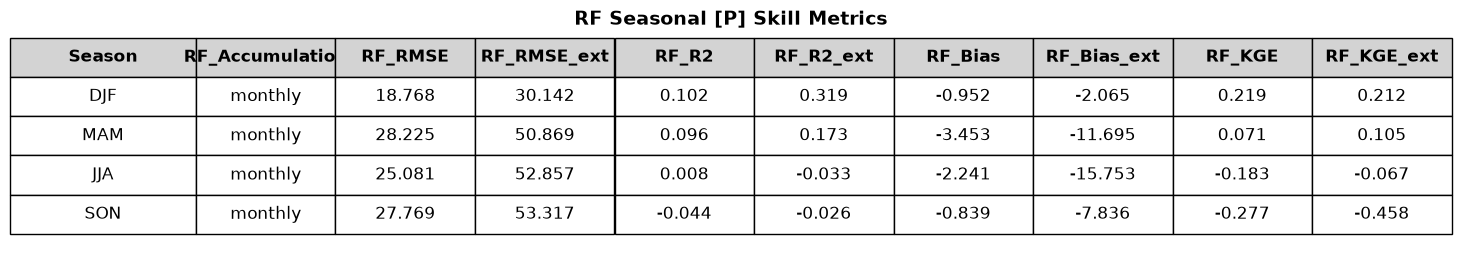

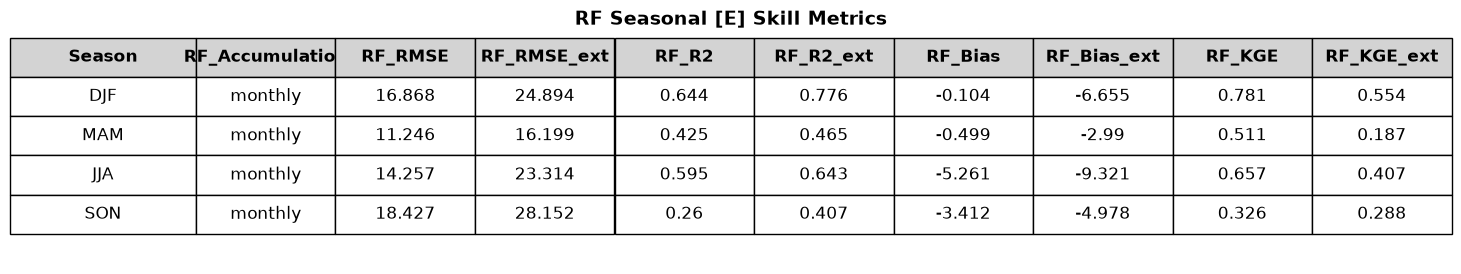

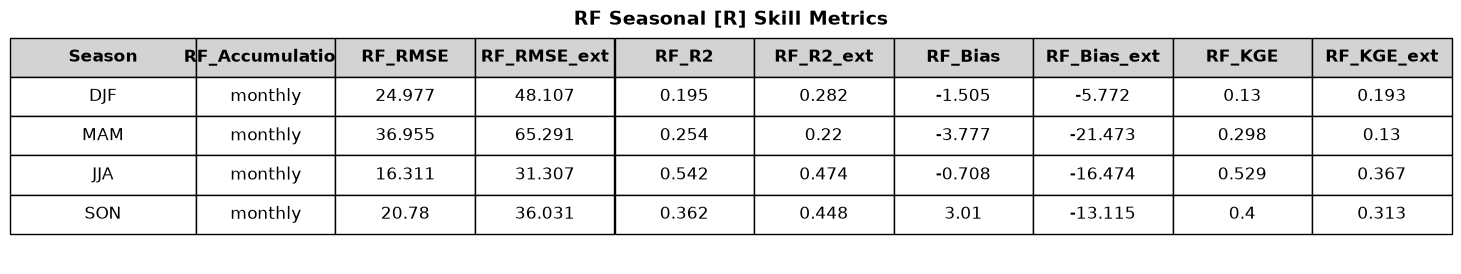

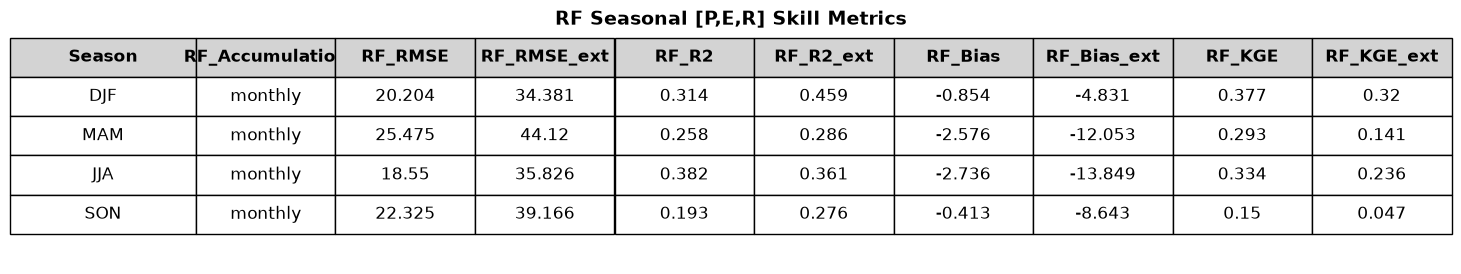

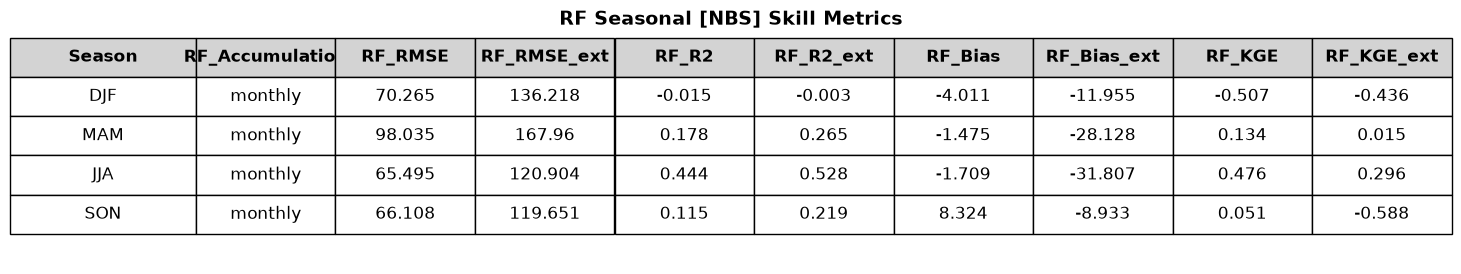

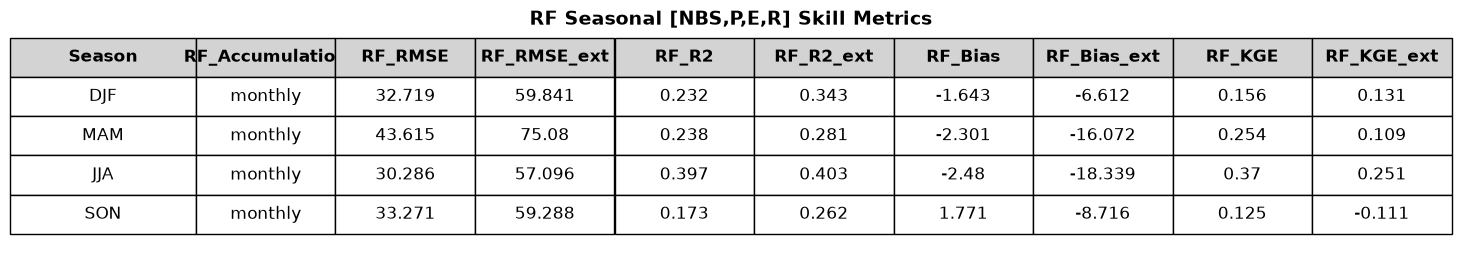

In [ ]:
lakes = ['superior', 'michigan-huron', 'erie', 'ontario']
models = ['RF']

component_configs = [
    (['precipitation'], "RF Seasonal [P] Skill Metrics"),
    (['evaporation'], "RF Seasonal [E] Skill Metrics"),
    (['runoff'], "RF Seasonal [R] Skill Metrics"),
    (['precipitation', 'evaporation', 'runoff'], "RF Seasonal [P,E,R] Skill Metrics"),
    (['nbs'], "RF Seasonal [NBS] Skill Metrics"),
    (['nbs', 'precipitation', 'evaporation', 'runoff'], "RF Seasonal [NBS,P,E,R] Skill Metrics"),
]

selected_metrics = [
    'RMSE', 'RMSE_ext',
    'R2', 'R2_ext',
    'Bias', 'Bias_ext',
    'KGE', 'KGE_ext'
]

seasons = ['DJF', 'MAM', 'JJA', 'SON']

# =========================
# MAIN LOOP (WITH PIVOT)
# =========================
for components, title in component_configs:

    seasonal_results = []

    for season in seasons:
        df_season = df[df['season'] == season]

        if df_season.empty:
            continue

        for model in models:

            skill = compute_skill(
                df_season,
                lakes=lakes,
                components=components,
                model=model,
                metrics=selected_metrics,
                date_col='forecast_month_dt'
            )

            skill['Season'] = season
            seasonal_results.append(skill)

    df_seasonal = pd.concat(seasonal_results, ignore_index=True)

    if df_seasonal.empty:
        continue

    # -------------------------
    # PIVOT TABLE
    # -------------------------
    df_pivot = df_seasonal.pivot(index='Season', columns='Model')

    # flatten multi-index columns
    df_pivot.columns = [f"{model}_{metric}" for metric, model in df_pivot.columns]

    df_pivot = df_pivot.reset_index()

    # enforce season order
    df_pivot['Season'] = pd.Categorical(df_pivot['Season'], categories=seasons, ordered=True)
    df_pivot = df_pivot.sort_values('Season')

    # -------------------------
    # PLOT
    # -------------------------
    plot_styled_table(
        df_pivot,
        title=title
    )